In [117]:
import sqlite3
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import ceil
from itertools import product
from ydata_profiling import ProfileReport
%config InlineBackend.figure_format = 'retina'
sns.set_theme()
main_color = "#379665"

# 1. Data exploration and initial analysis

In [69]:
df_raw = pd.read_csv(r"C:\Users\35191\Downloads\acdc_dataset (1).csv", sep=";", index_col="member_id")
df = df_raw.copy()
df_raw.head()

,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
member_id,,,,,,,,,,,,,,,,,,,,,
CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,2023-03-06,...,False,True,0,False,True,True,False,False,2,4477.97
CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,1970-01-01,...,False,False,0,True,False,False,False,False,0,165.86
CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,1970-01-01,...,False,False,0,False,False,False,False,False,1,4486.17
CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,2022-02-15,...,False,False,0,False,False,False,False,False,0,258.63
CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,1970-01-01,...,False,False,0,False,False,True,False,False,0,335.74


In [70]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
Index: 15465 entries, CW000001 to CW015101
Data columns (total 30 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   age                          14907 non-null  float64
 1   gender                       14935 non-null  object 
 2   industry                     15465 non-null  object 
 3   country                      15035 non-null  object 
 4   is_team_account              15465 non-null  bool   
 5   n_colleagues_on_account      15465 non-null  int64  
 6   plan_tier                    15360 non-null  object 
 7   plan_days_per_week           15465 non-null  int64  
 8   membership_start             15465 non-null  object 
 9   membership_end               15465 non-null  object 
 10  last_badge_swipe             15465 non-null  object 
 11  days_since_last_visit        15465 non-null  int64  
 12  total_visits                 15465 non-null  int64  
 13  avg_weekly_

In [71]:
df_raw.columns

Index(['age', 'gender', 'industry', 'country', 'is_team_account',
       'n_colleagues_on_account', 'plan_tier', 'plan_days_per_week',
       'membership_start', 'membership_end', 'last_badge_swipe',
       'days_since_last_visit', 'total_visits', 'avg_weekly_visits',
       'entitled_visits_last_period', 'actual_visits_last_period',
       'meeting_room_hours', 'event_space_hours', 'guest_passes_issued',
       'uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes',
       'uses_print', 'uses_mail_handling', 'uses_phone_booths',
       'uses_day_passes', 'uses_storage', 'uses_bike_locker', 'n_renewals',
       'lifetime_value'],
      dtype='object')

In [72]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
age,14907.0,34.858724,10.394649,1.0,29.00,34.00,40.00,149.00
n_colleagues_on_account,15465.0,0.537019,1.177668,-1.0,0.00,0.00,1.00,9.00
plan_days_per_week,15465.0,3.387262,1.458818,0.0,2.00,3.00,5.00,9.00
days_since_last_visit,15465.0,117.109279,275.532807,-956.0,4.00,13.00,55.00,1212.00
total_visits,15465.0,110.406531,182.939340,-112.0,8.00,34.00,132.00,6530.00
avg_weekly_visits,15465.0,1.777214,1.937515,0.0,0.71,1.42,2.41,47.40
entitled_visits_last_period,15465.0,27.517393,13.480235,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15465.0,13.800970,11.387207,0.0,5.00,10.00,20.00,60.00
meeting_room_hours,14167.0,33.075570,428.169678,-56.6,0.00,0.00,7.20,41220.00
event_space_hours,15465.0,5.117220,26.013097,-13.5,0.00,0.00,0.00,602.80


In [73]:
df_raw.describe(include="bool").T

,count,unique,top,freq
is_team_account,15465,2,False,11112
uses_meeting_rooms,15465,2,False,10202
uses_event_space,15465,2,False,13624
uses_guest_passes,15465,2,False,12651
uses_mail_handling,15465,2,False,11901
uses_phone_booths,15465,2,False,11469
uses_day_passes,15465,2,False,12069
uses_storage,15465,2,False,13169
uses_bike_locker,15465,2,False,15439


In [74]:
df_raw.describe(include="object").T
#plan tier should only have 5 unique values
#gender shou have 3: Female, Male, Other

,count,unique,top,freq
gender,14935,12,Female,7414
industry,15465,43,Information Technology,3322
country,15035,33,Portugal,9959
plan_tier,15360,19,flex,5182
membership_start,15465,1539,2021-01-01,560
membership_end,15465,1423,1970-01-01,3956
last_badge_swipe,15465,1543,2023-12-30,279
lifetime_value,14425,11860,0,1725


# 2. Data quality checks

In [75]:
df['membership_start'] = pd.to_datetime(df["membership_start"], format='mixed')
df['membership_end'] = pd.to_datetime(df["membership_end"], format='mixed')
df['last_badge_swipe'] = pd.to_datetime(df["last_badge_swipe"], format='mixed')

We turned the variable `lifetime_value` to a float. The variable had symbols that made them into an object type.

In [76]:
df["lifetime_value"] = (
    df["lifetime_value"]
    .str.replace("€", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
    .astype(float)
)

In [77]:
df_raw["uses_print"].unique()

array([0, 1])

`uses_print` only has the values 1 and 0, so we turn it into a boolean type.

In [78]:
df["uses_print"] = df["uses_print"].astype("boolean")
df["uses_print"].dtype

BooleanDtype

In [79]:
df.isna().sum()[lambda s: s > 0]

age                     558
gender                  530
country                 430
plan_tier               105
meeting_room_hours     1298
guest_passes_issued    1271
lifetime_value         1040
dtype: int64

In [80]:
#Turning object values to lower case
cols_object = df.select_dtypes(include="object").columns
df[cols_object] = df[cols_object].apply(lambda s: s.str.lower())

print(f"Gender unique values: {df["gender"].unique()}")
print(f"Country unique values: {df["country"].unique()}")
print(f"Plan tier unique values: {df["plan_tier"].unique()}")
print(f"Industry unique values: {df["industry"].unique()}")

Gender unique values: ['female' 'male' 'f' 'other' nan ' female' 'm' ' male' ' other' 'o']
Country unique values: ['portugal' 'de' 'united kingdom' 'spain' 'germany' 'netherlands' 'france'
 'pt' 'other (europe)' 'portucal' nan 'uk' 'ireland' 'ie' 'portugal '
 'deutschland' 'u.k.' 'gb' 'es' 'nl' 'españa' 'espana' 'the netherlands'
 'fr' 'holland']
Plan tier unique values: ['flex' 'hot_desk' 'dedicated_desk' 'full_time' 'private_office'
 'hot desk' 'dedicateddesk' nan 'hotdesk' 'fulltime' 'privateoffice'
 'full time' 'dedicated desk' 'private office']
Industry unique values: ['information technology' 'education' 'legal' 'health' 'unknown' 'other'
 'consulting' 'design & creative' 'finance' 'marketing & pr'
 'marketing and pr' 'real estate' 'marketing/pr' 'design/creative'
 'realestate' 'it' 'tech' 'design and creative' 'real-estate']


In [81]:
#Replacing gender values
df["gender"] = df["gender"].replace([" female", "f"], "female")
df["gender"] = df["gender"].replace([" male", "m"], "male")
df["gender"] = df["gender"].replace([" other", "o"], "other")

#Replacing country values
df["country"] = df["country"].replace({
    "portucal":"portugal", "portugal ":"portugal",
    "de":"germany", "deutschland":"germany",
    "uk":"united kingdom", "u.k.":"united kingdom",
    "es":"spain", "españa":"spain", "espana":"spain",
    "fr":"france",
    "ie":"ireland"
})

#Replacing Plan tier values
df["plan_tier"] = df["plan_tier"].replace(["hotdesk", "hot desk"], "hot_desk")
df["plan_tier"] = df["plan_tier"].replace(["dedicateddesk", "dedicated desk"], "dedicated_desk")
df["plan_tier"] = df["plan_tier"].replace(["fulltime", "full time"], "full_time")
df["plan_tier"] = df["plan_tier"].replace(["privateoffice", "private office"], "private_office")

#Replacing Industry values
df["industry"] = df["industry"].replace(["it", "tech"], "information technology")
df["industry"] = df["industry"].replace(["design & creative", "design/creative"], "design and creative")
df["industry"] = df["industry"].replace(["marketing & pr", "marketing/pr"], "marketing and pr")
df["industry"] = df["industry"].replace(["realestate", "real-estate"], "real estate")

df.describe(include="object").T

,count,unique,top,freq
gender,14935,3,female,7867
industry,15465,11,information technology,3559
country,15035,13,portugal,10378
plan_tier,15360,5,flex,5453


In [82]:
df.duplicated().sum()

np.int64(293)

In [83]:
df_nodups = df.drop_duplicates()

In [84]:
non_metric_features = [
    'gender', 'country', 'industry', 'plan_tier', 'is_team_account',
    'uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes',
    'uses_print', 'uses_mail_handling', 'uses_phone_booths', 'uses_day_passes',
    'uses_storage', 'uses_bike_locker'
]
date_features = ['membership_start', 'membership_end', 'last_badge_swipe']
metric_features = df.columns.drop(non_metric_features + date_features).to_list()

In [85]:
df_metrics = df_nodups[metric_features]

neg_counts = (df_metrics < 0).sum()

print("Variables with negative values:")
print(neg_counts[neg_counts > 0])

Variables with negative values:
n_colleagues_on_account    557
days_since_last_visit       56
total_visits                42
meeting_room_hours          16
event_space_hours            8
guest_passes_issued          7
n_renewals                  65
lifetime_value              81
dtype: int64


In [86]:
(df_nodups['plan_days_per_week'] > 7).sum()

np.int64(53)

# 3. Metric features visualizations

## 3.1. Univariate Analysis

### 3.1.1. Age

What if we filter out the "weird values"? Age < 18 and Age > 90, since it is a coworking space, those ages are the most logical.

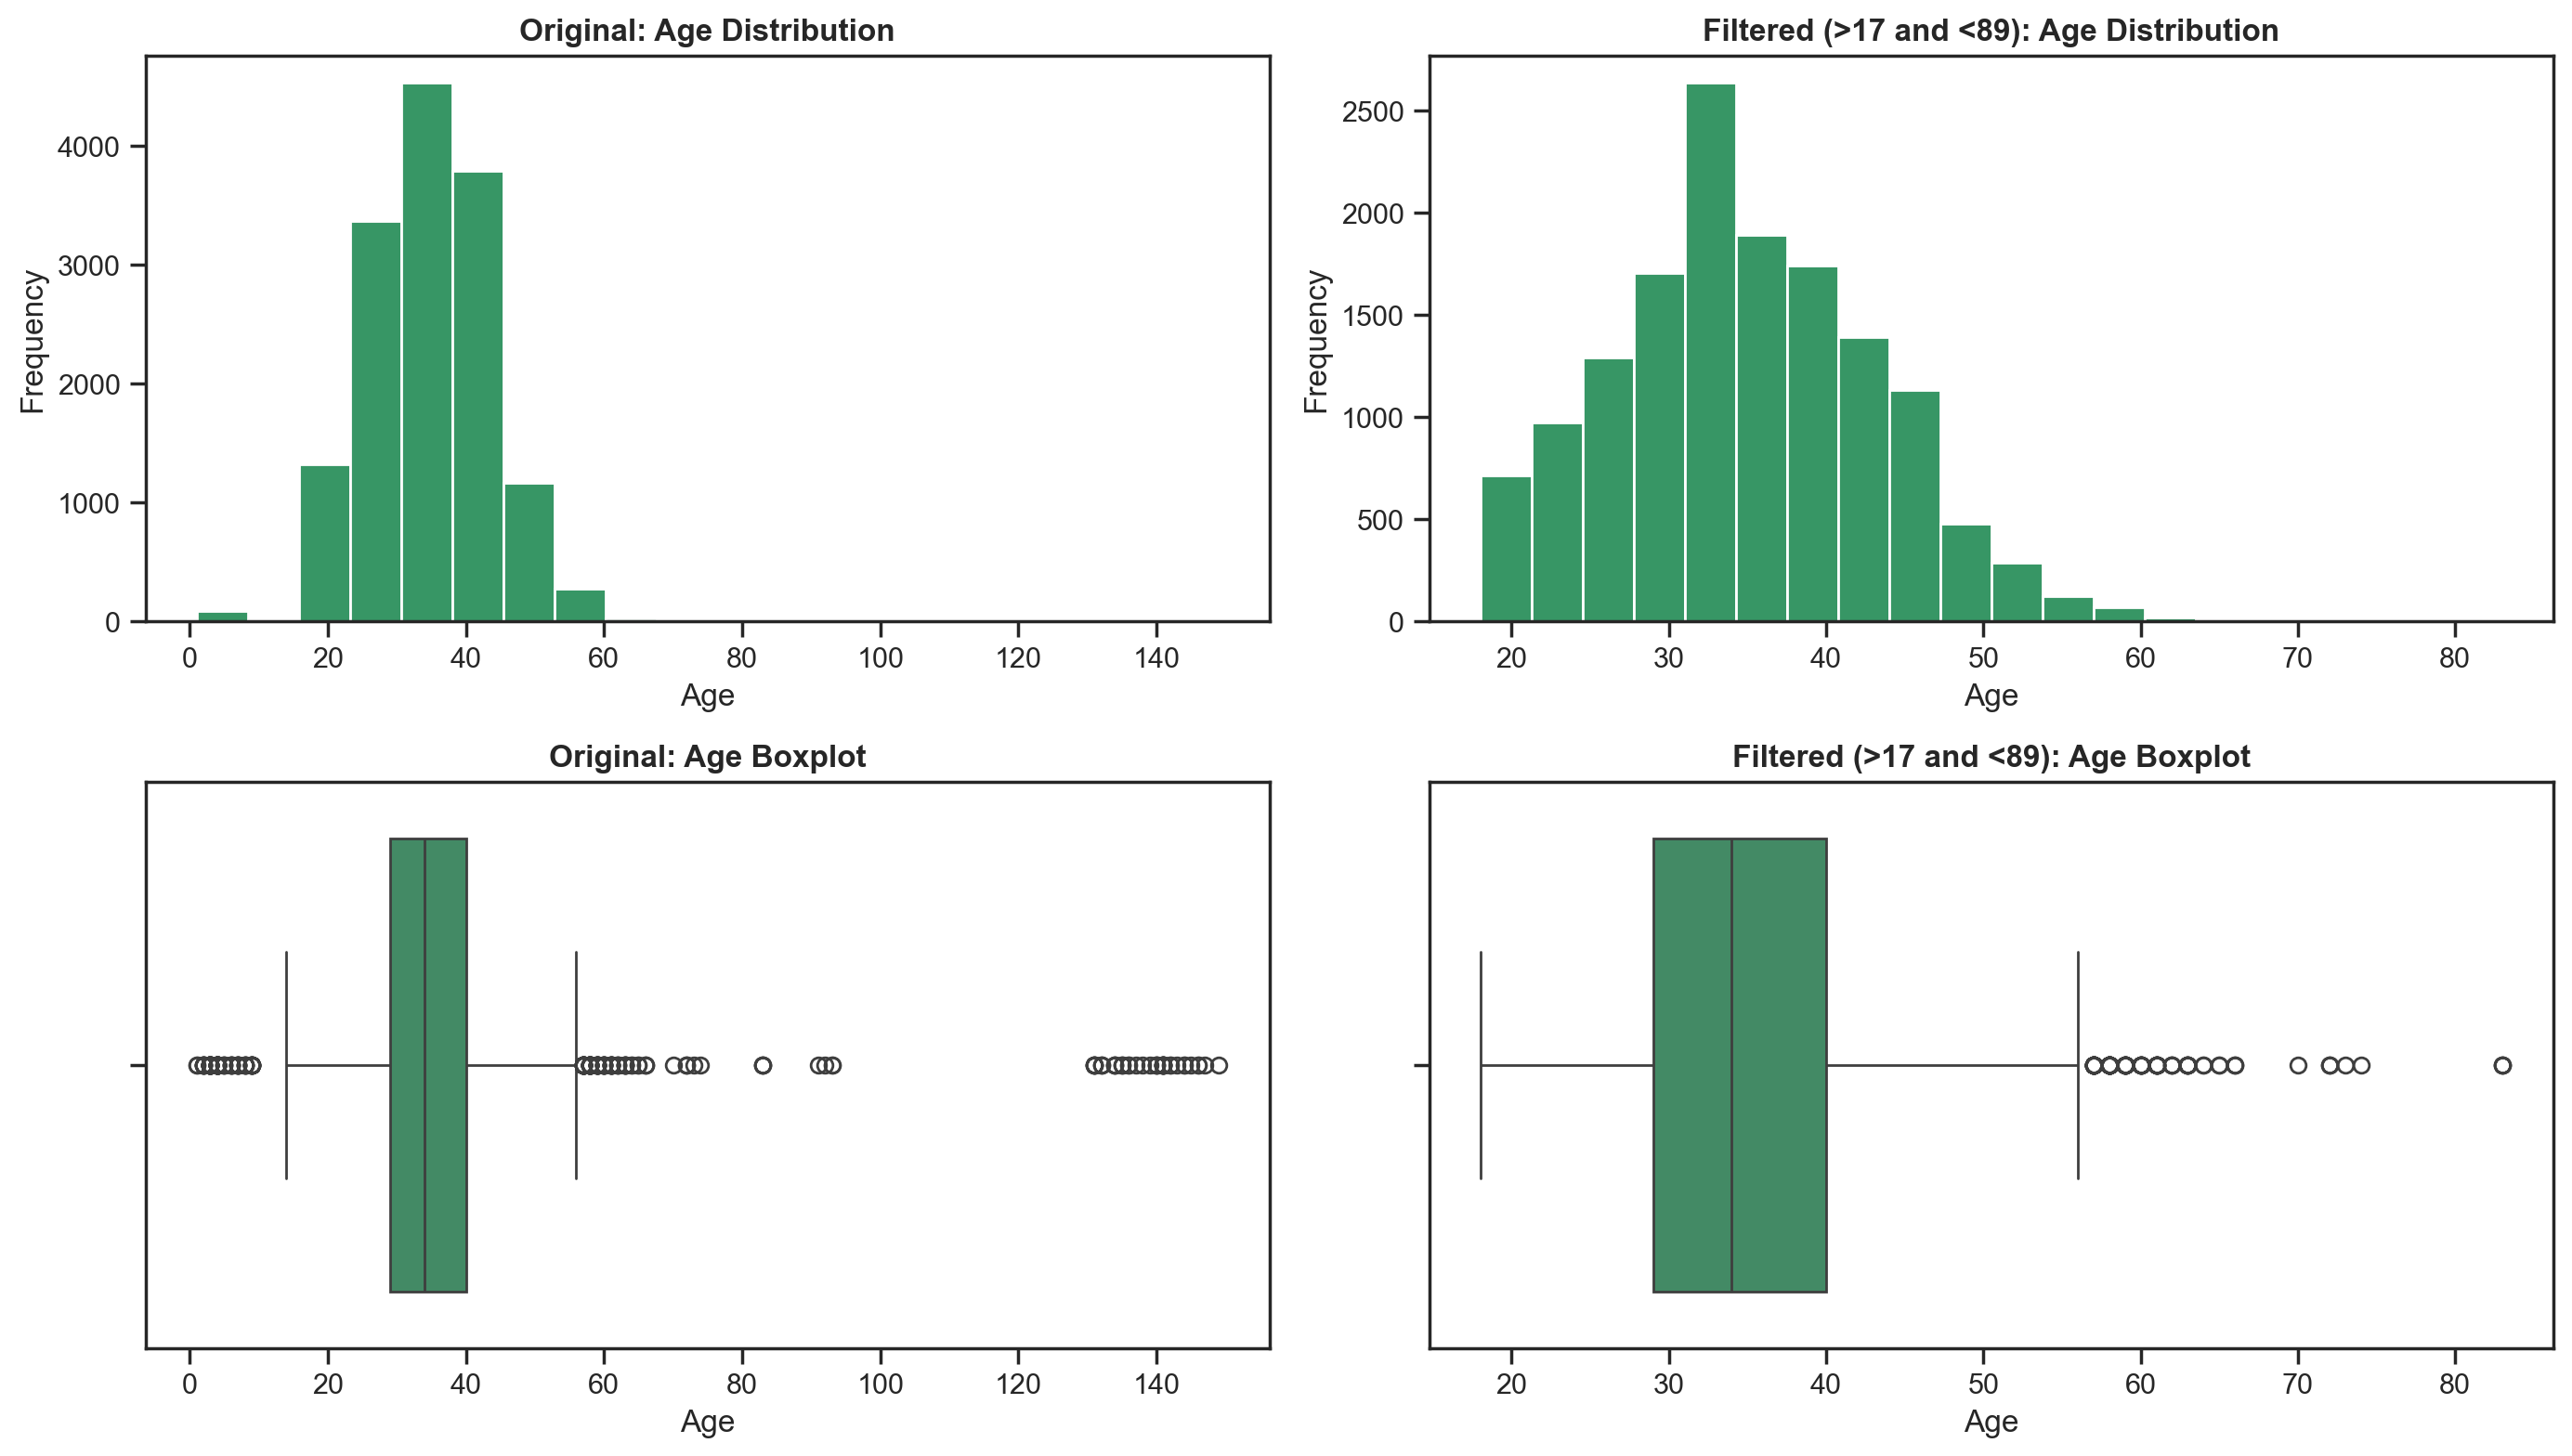

In [120]:
subplot_figsize = (14, 8)

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(
        2, # nrows
        2, # ncols
        figsize=subplot_figsize)

df_age_filtered = df_nodups[(df_nodups["age"] > 17) & (df_nodups["age"] < 89)]

axes[0, 0].hist(df_nodups["age"].dropna(), bins=20, color=main_color)
axes[0, 1].hist(df_age_filtered["age"].dropna(), bins=20, color=main_color)

sns.boxplot(x=df_nodups["age"], color=main_color, ax=axes[1, 0])
sns.boxplot(x=df_age_filtered["age"], color=main_color, ax=axes[1, 1])

axes[0, 0].set_title('Original: Age Distribution', fontweight="bold") 
axes[0, 0].set_xlabel('Age')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].set_title('Filtered (>17 and <89): Age Distribution', fontweight="bold") 
axes[0, 1].set_xlabel('Age')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].set_title('Original: Age Boxplot', fontweight="bold") 
axes[1, 0].set_xlabel('Age')

axes[1, 1].set_title('Filtered (>17 and <89): Age Boxplot', fontweight="bold") 
axes[1, 1].set_xlabel('Age')

plt.tight_layout()
plt.show()

### 3.1.2. n_colleagues_on_account	

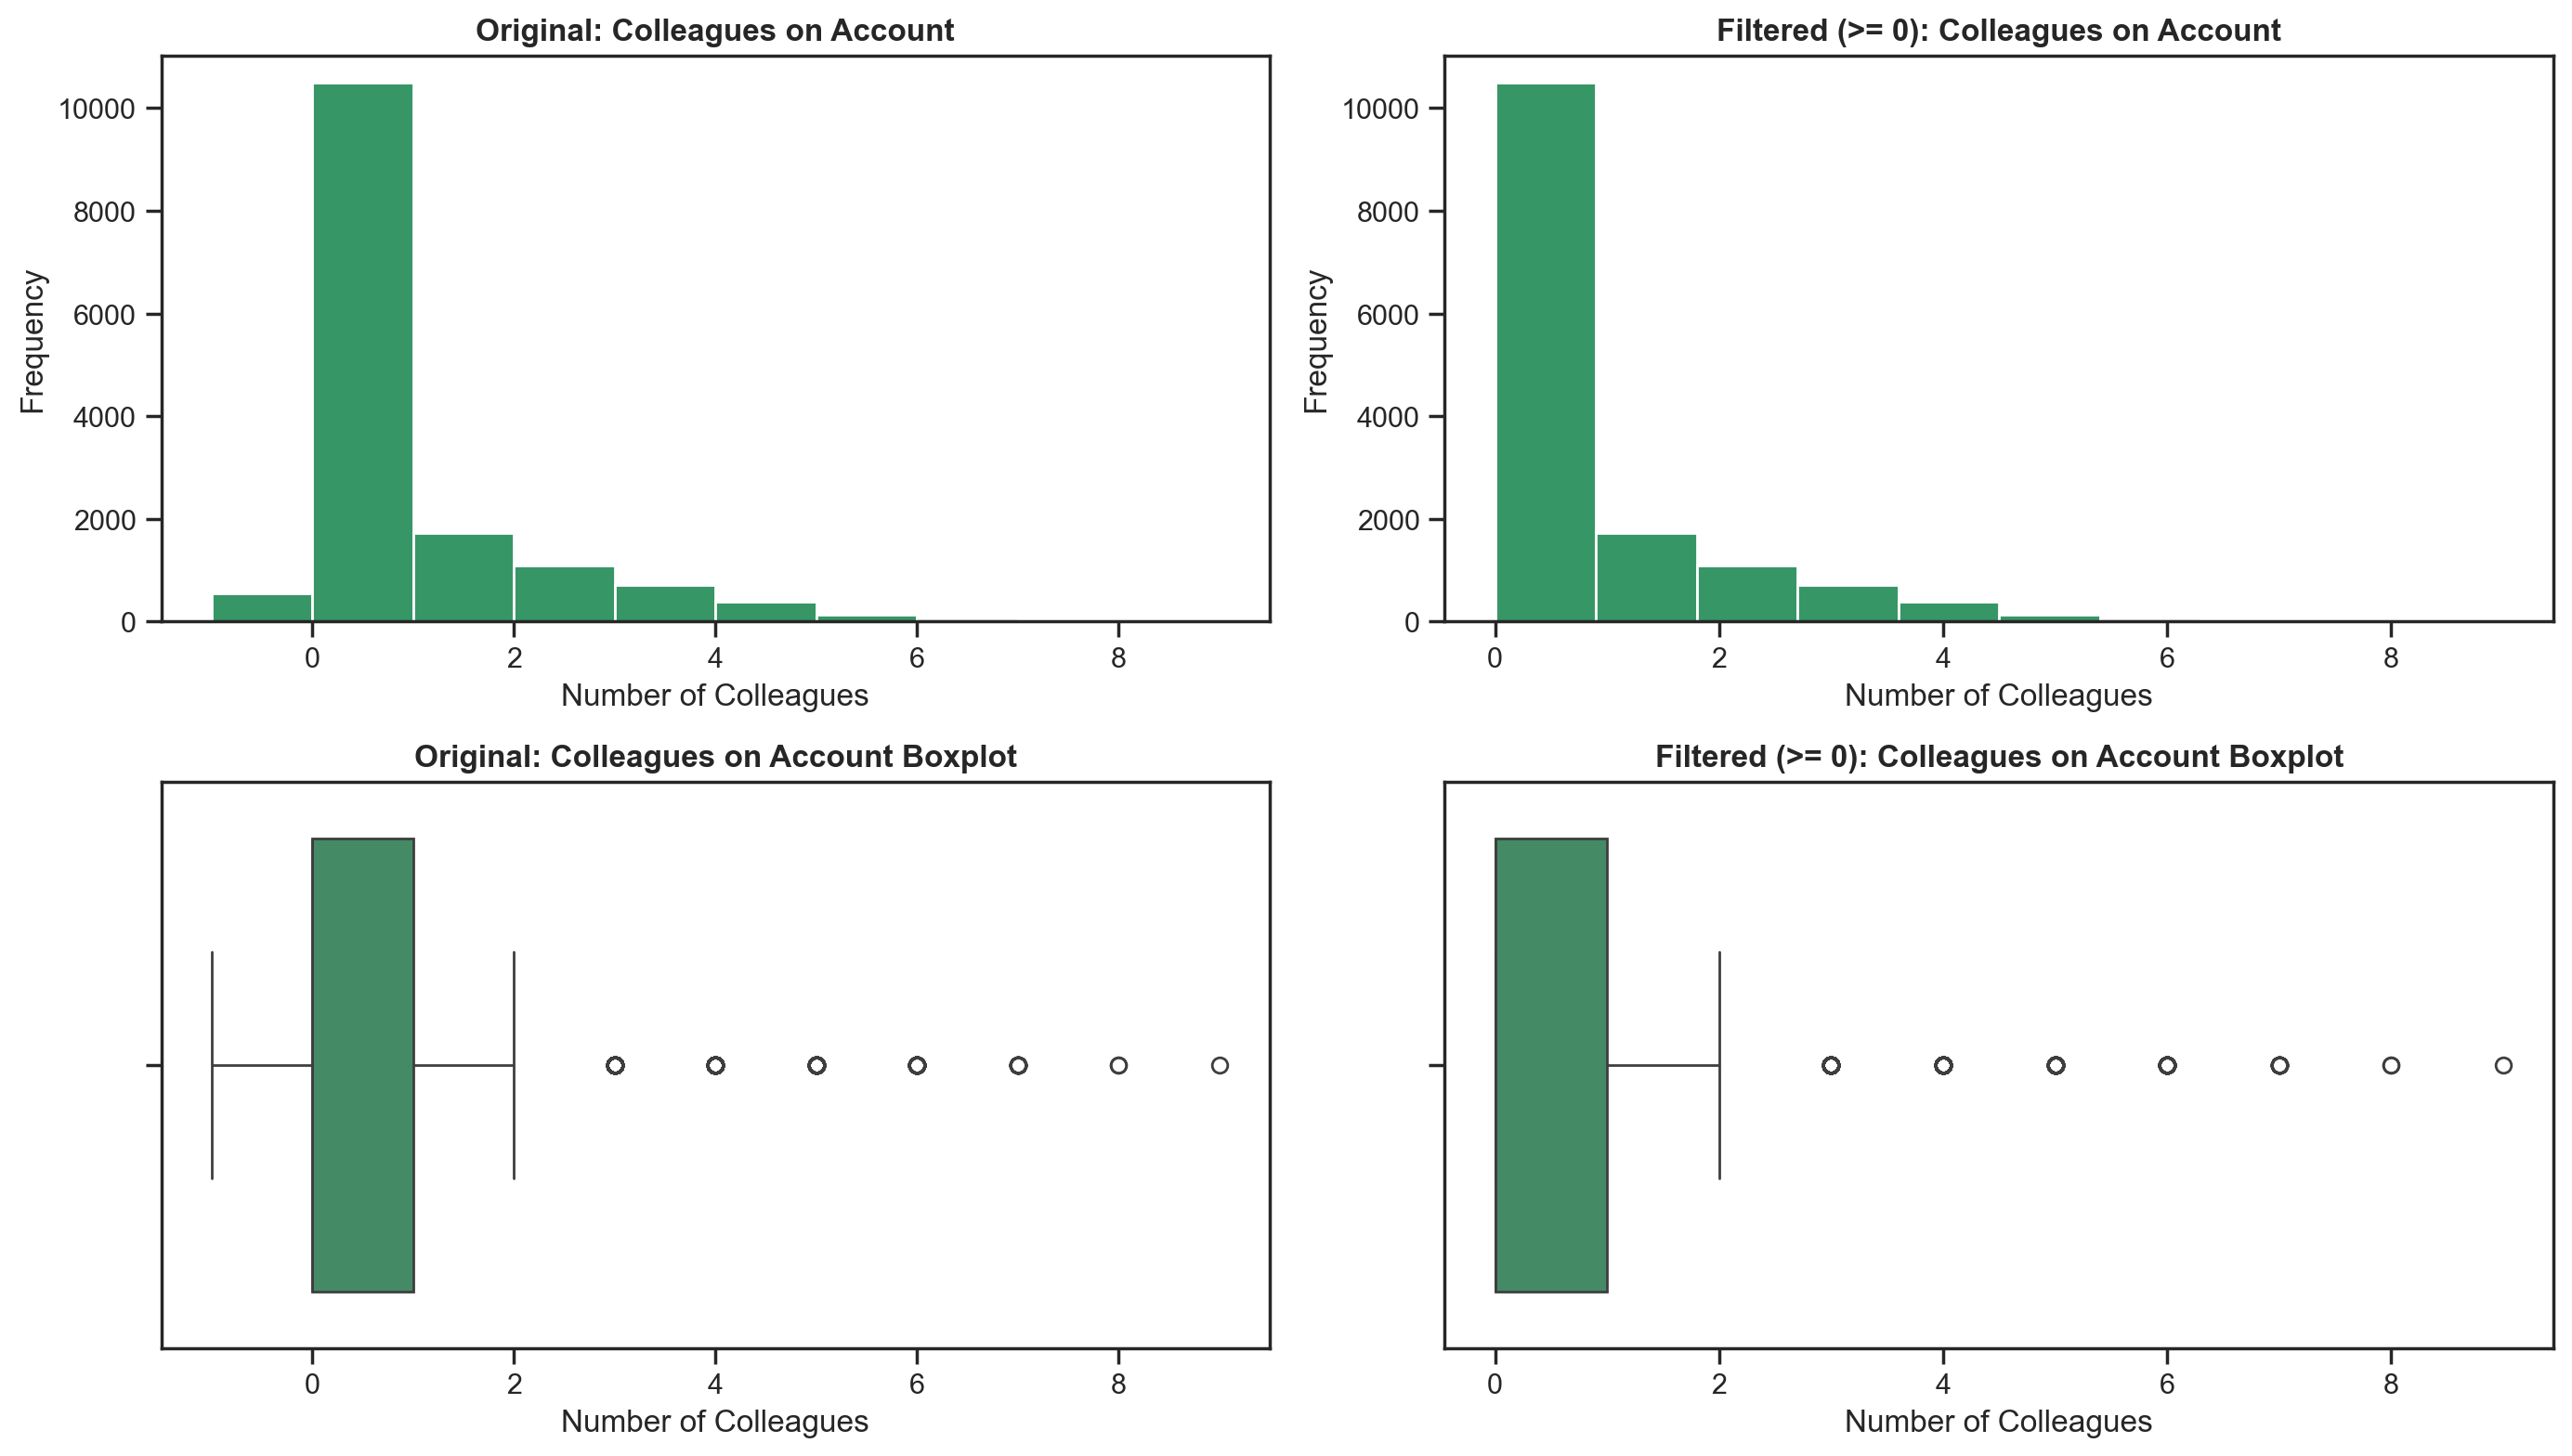

In [121]:
subplot_figsize = (14, 8)

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(
        2, # nrows
        2, # ncols
        figsize=subplot_figsize)

df_colleagues_clean = df_nodups[df_nodups["n_colleagues_on_account"] >= 0]

axes[0, 0].hist(df_nodups["n_colleagues_on_account"].dropna(), bins=10, color=main_color)
axes[0, 1].hist(df_colleagues_clean["n_colleagues_on_account"].dropna(), bins=10, color=main_color)
sns.boxplot(x=df_nodups["n_colleagues_on_account"], color=main_color, ax=axes[1, 0])
sns.boxplot(x=df_colleagues_clean["n_colleagues_on_account"], color=main_color, ax=axes[1, 1])

axes[0, 0].set_title('Original: Colleagues on Account', fontweight="bold") 
axes[0, 0].set_xlabel('Number of Colleagues')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].set_title('Filtered (>= 0): Colleagues on Account', fontweight="bold") 
axes[0, 1].set_xlabel('Number of Colleagues')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].set_title('Original: Colleagues on Account Boxplot', fontweight="bold") 
axes[1, 0].set_xlabel('Number of Colleagues')

axes[1, 1].set_title('Filtered (>= 0): Colleagues on Account Boxplot', fontweight="bold") 
axes[1, 1].set_xlabel('Number of Colleagues')

plt.tight_layout()
plt.show()

### 3.1.3. plan_days_per_week

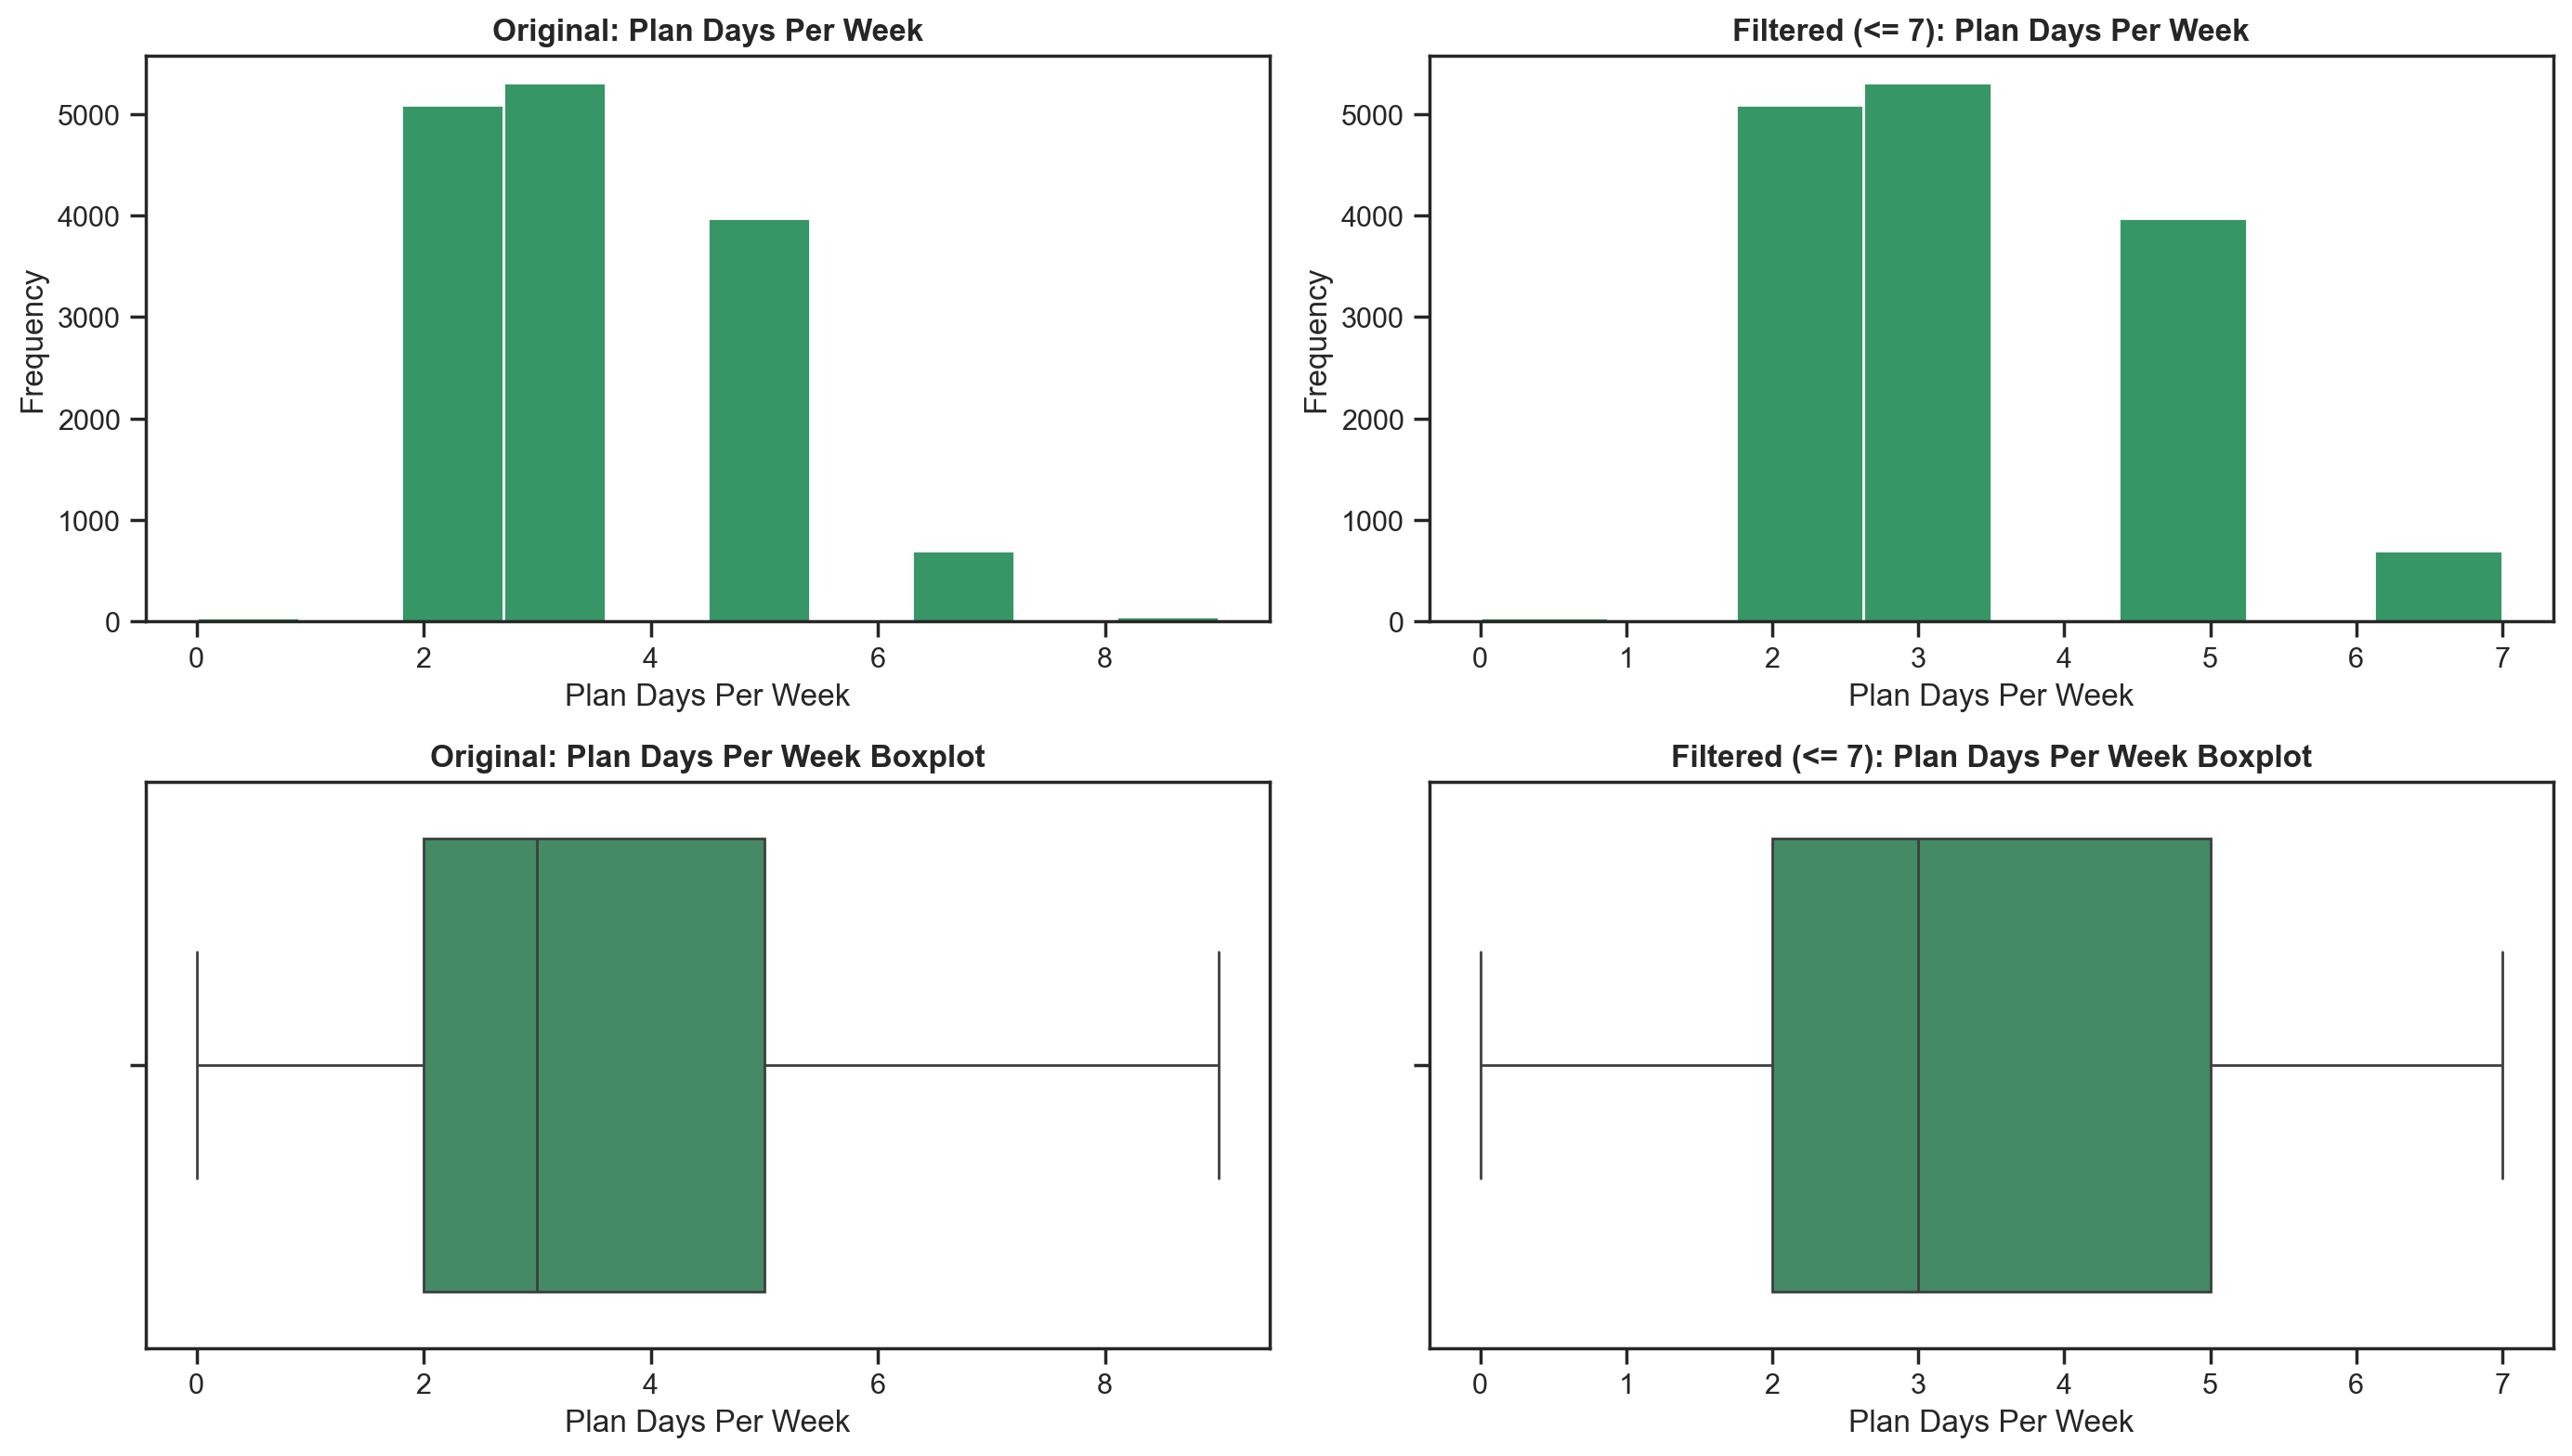

In [122]:
subplot_figsize = (14, 8)

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(
        2, # nrows
        2, # ncols
        figsize=subplot_figsize)

df_plan_clean = df_nodups[df_nodups["plan_days_per_week"] <= 7]

axes[0, 0].hist(df_nodups["plan_days_per_week"].dropna(), bins=10, color=main_color)
axes[0, 1].hist(df_plan_clean["plan_days_per_week"].dropna(), bins=8, color=main_color)

sns.boxplot(x=df_nodups["plan_days_per_week"], color=main_color, ax=axes[1, 0])
sns.boxplot(x=df_plan_clean["plan_days_per_week"], color=main_color, ax=axes[1, 1])

axes[0, 0].set_title('Original: Plan Days Per Week', fontweight="bold") 
axes[0, 0].set_xlabel('Plan Days Per Week')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].set_title('Filtered (<= 7): Plan Days Per Week', fontweight="bold") 
axes[0, 1].set_xlabel('Plan Days Per Week')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].set_title('Original: Plan Days Per Week Boxplot', fontweight="bold") 
axes[1, 0].set_xlabel('Plan Days Per Week')

axes[1, 1].set_title('Filtered (<= 7): Plan Days Per Week Boxplot', fontweight="bold") 
axes[1, 1].set_xlabel('Plan Days Per Week')

plt.tight_layout()
plt.show()

### 3.1.4. days_since_last_visit

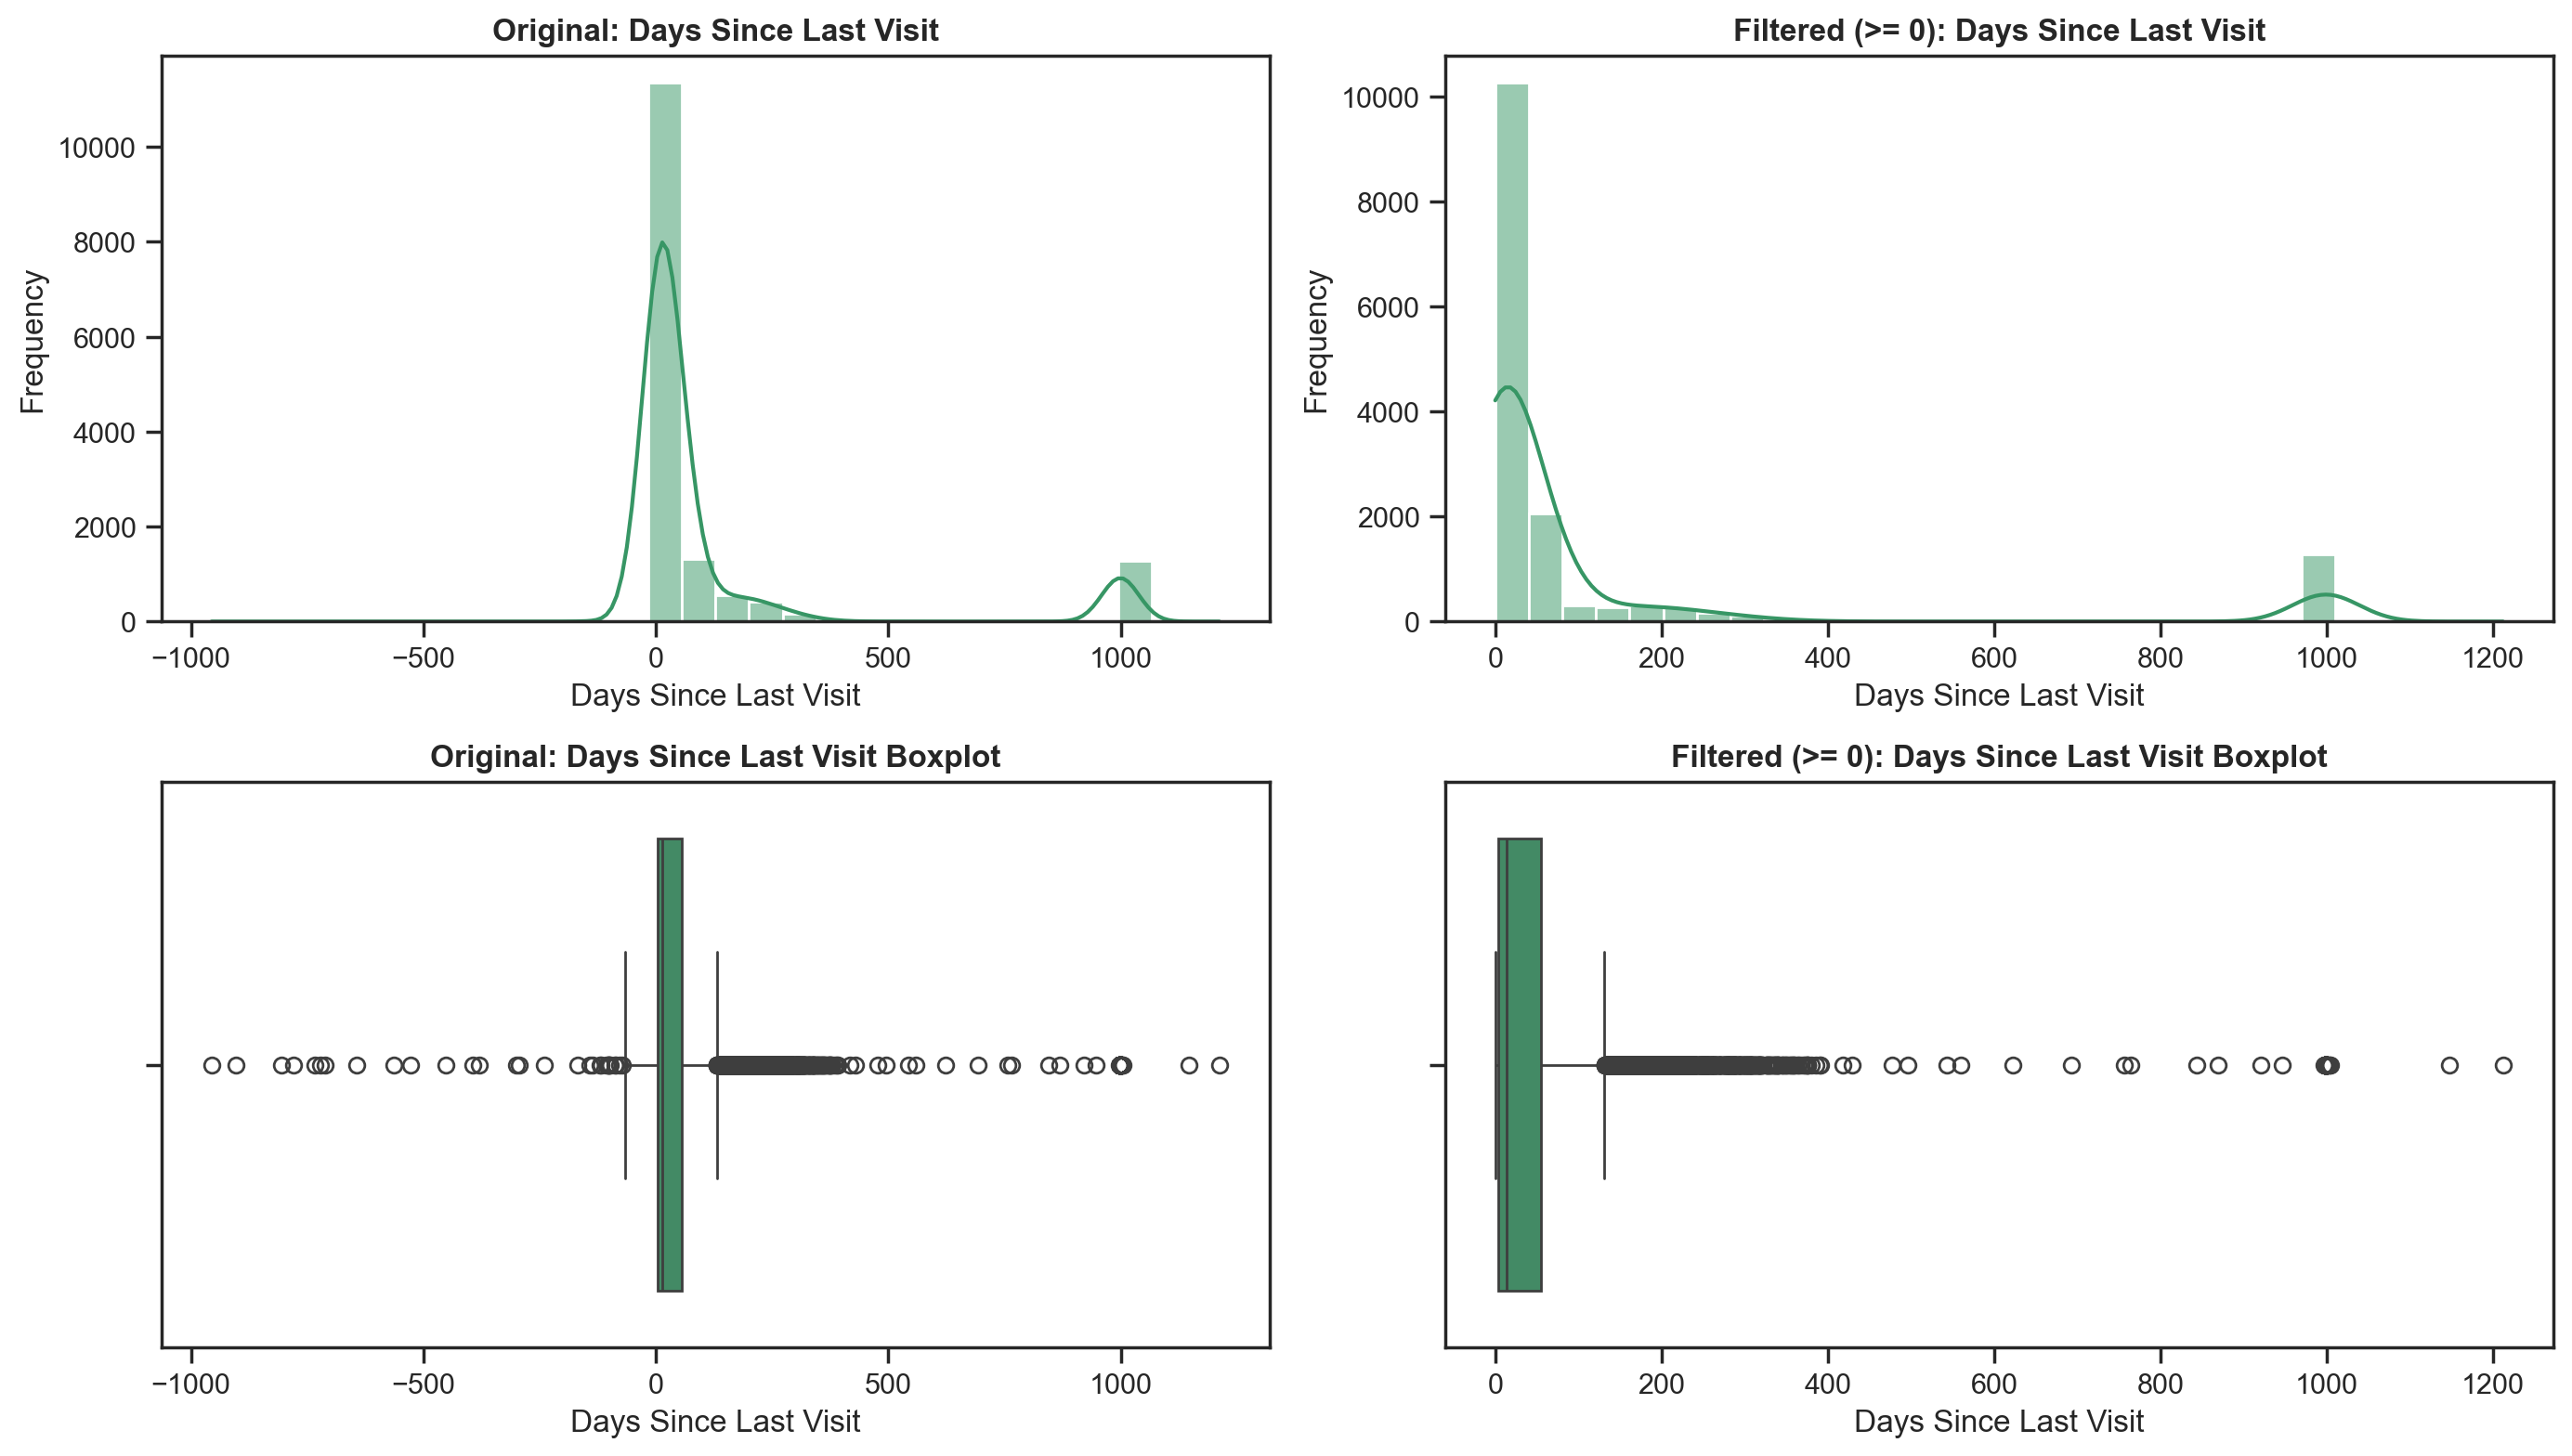

In [123]:
subplot_figsize = (14, 8)

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(
        2, # nrows
        2, # ncols
        figsize=subplot_figsize)

df_recency_clean = df_nodups[df_nodups["days_since_last_visit"] >= 0]

sns.histplot(df_nodups["days_since_last_visit"].dropna(), bins=30, color=main_color, kde=True, ax=axes[0, 0])
sns.histplot(df_recency_clean["days_since_last_visit"].dropna(), bins=30, color=main_color, kde=True, ax=axes[0, 1])

sns.boxplot(x=df_nodups["days_since_last_visit"], color=main_color, ax=axes[1, 0])
sns.boxplot(x=df_recency_clean["days_since_last_visit"], color=main_color, ax=axes[1, 1])

axes[0, 0].set_title('Original: Days Since Last Visit', fontweight="bold")
axes[0, 0].set_xlabel('Days Since Last Visit')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].set_title('Filtered (>= 0): Days Since Last Visit', fontweight="bold")
axes[0, 1].set_xlabel('Days Since Last Visit')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].set_title('Original: Days Since Last Visit Boxplot', fontweight="bold")
axes[1, 0].set_xlabel('Days Since Last Visit')

axes[1, 1].set_title('Filtered (>= 0): Days Since Last Visit Boxplot', fontweight="bold")
axes[1, 1].set_xlabel('Days Since Last Visit')

plt.tight_layout()
plt.show()

### 3.1.5. days_since_last_visit and avg_weekly_visits

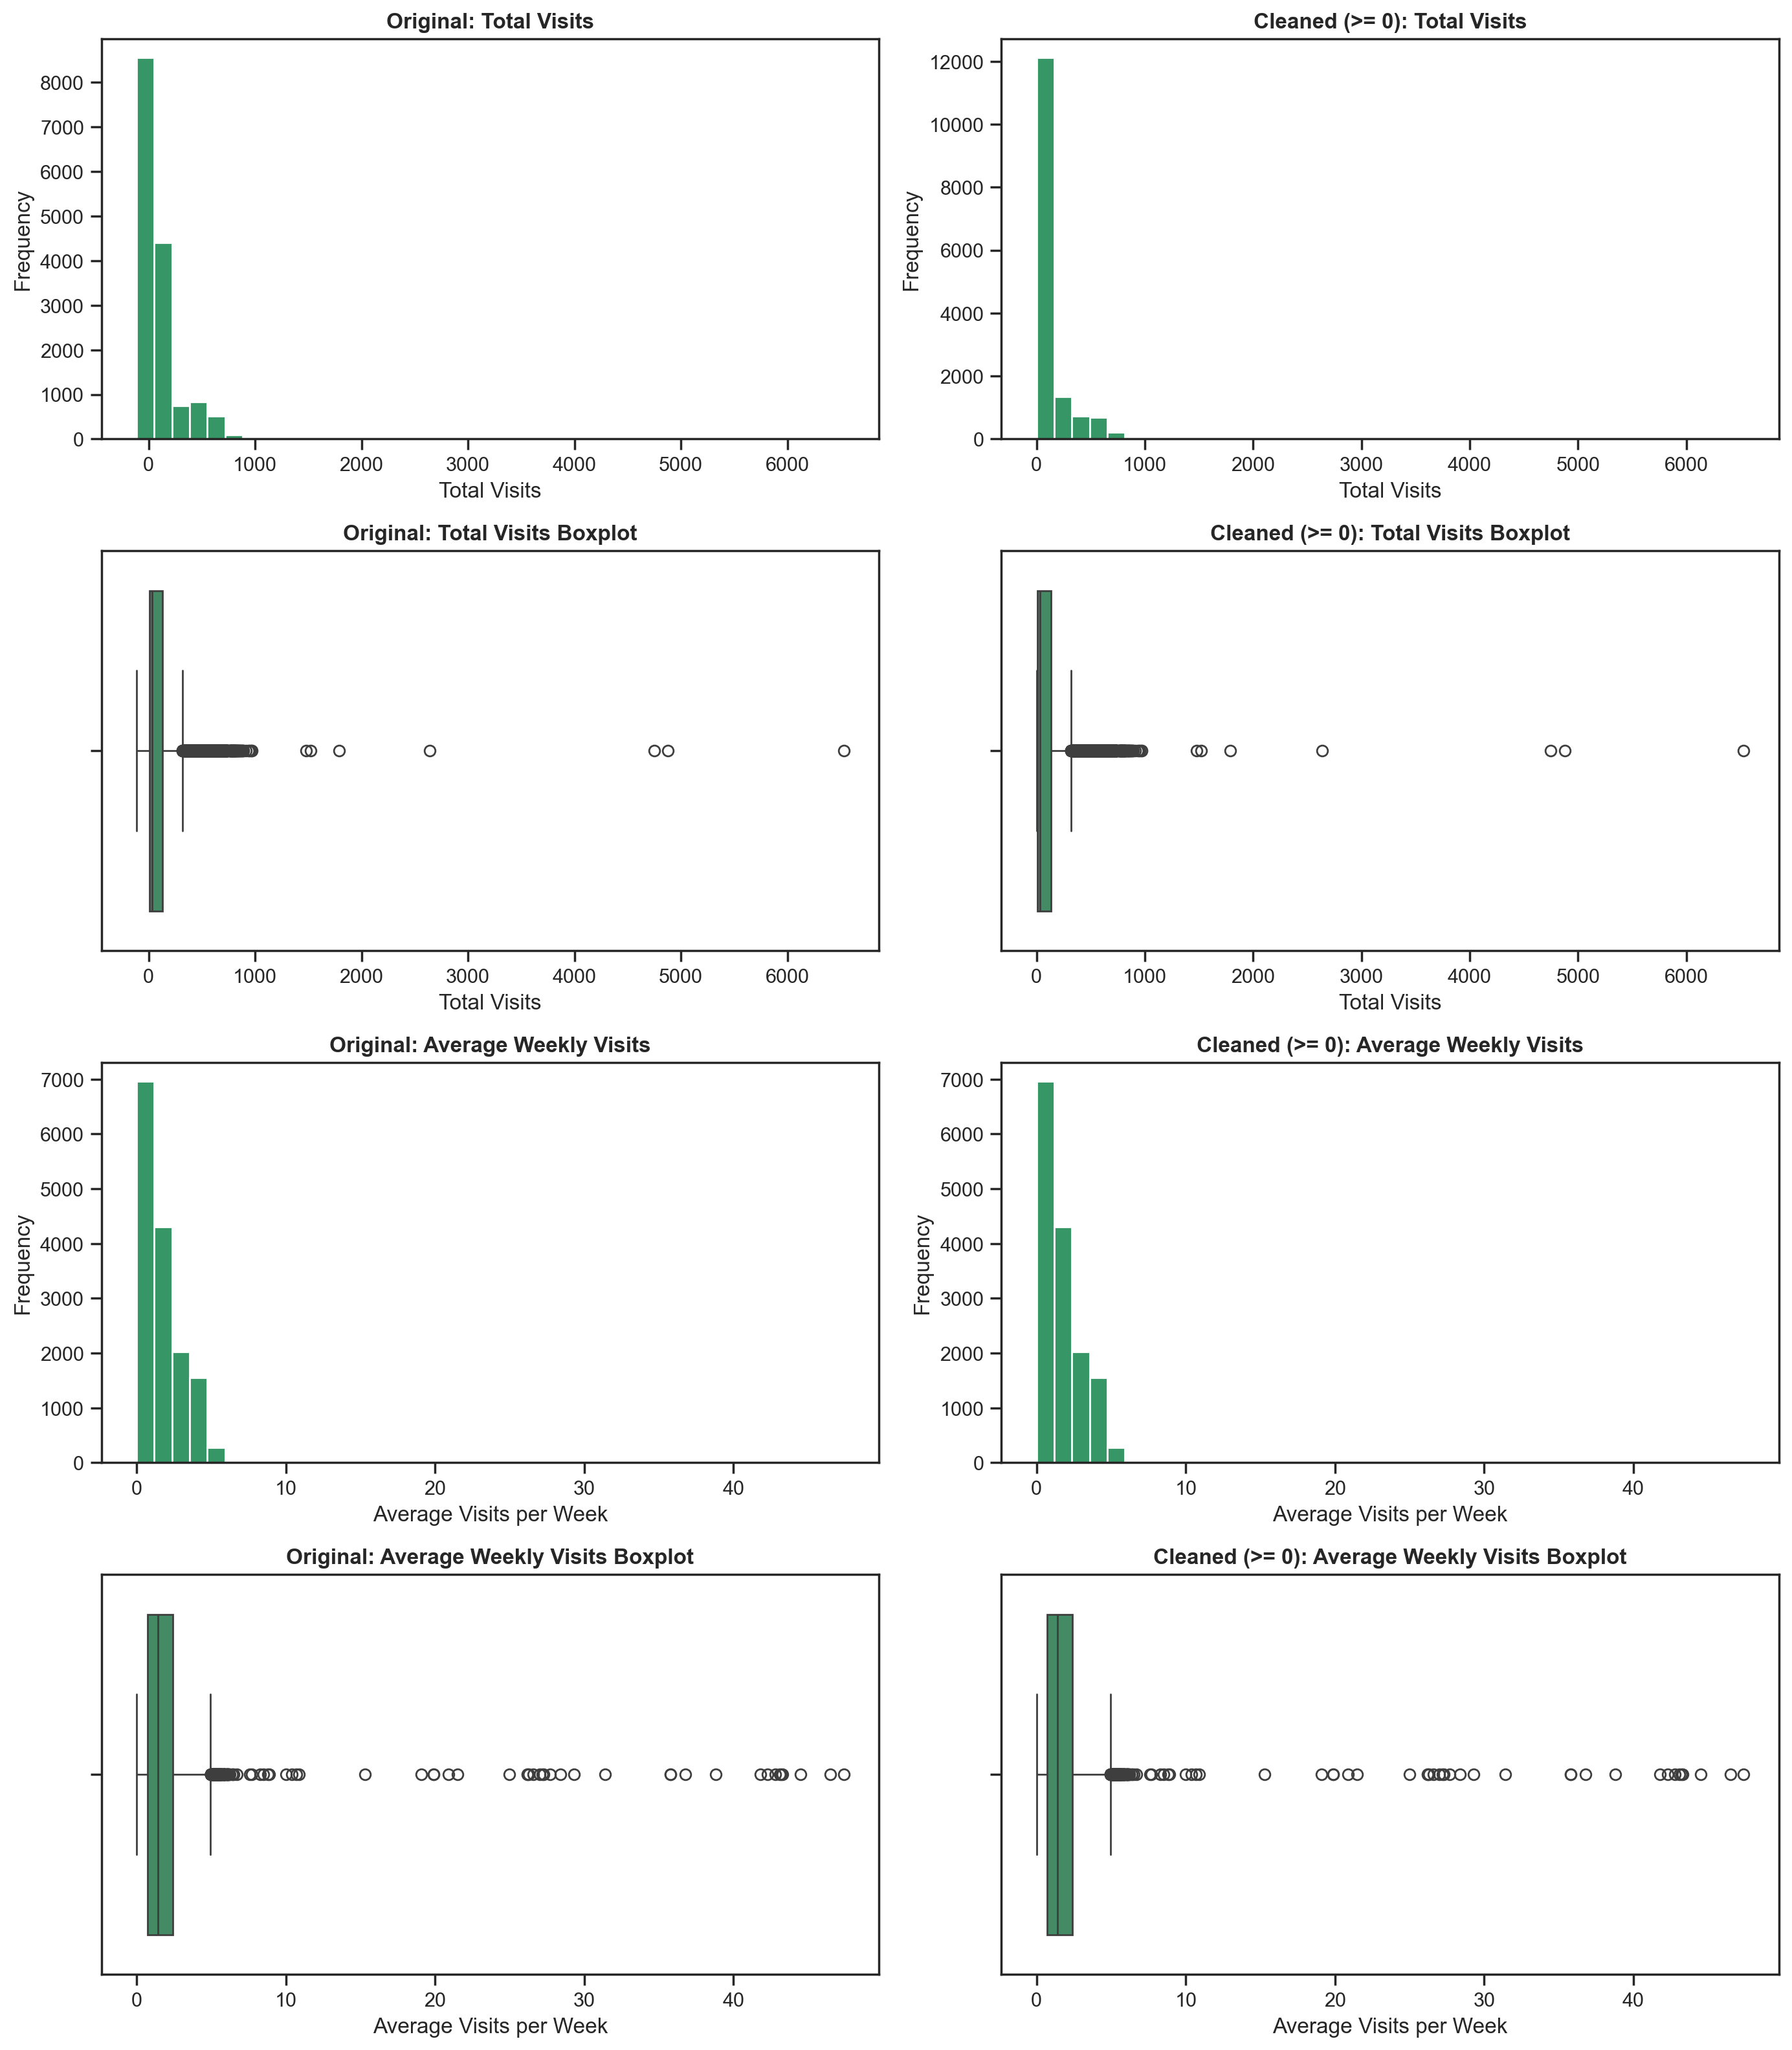

In [124]:
df_visits_clean = df_nodups[df_nodups["total_visits"] >= 0]
df_avg_clean = df_nodups[df_nodups["avg_weekly_visits"] >= 0]

subplot_figsize = (14, 16) 

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(
        4, # nrows
        2, # ncols
        figsize=subplot_figsize)

# total_visits

axes[0, 0].hist(df_nodups["total_visits"].dropna(), bins=40, color=main_color)
axes[0, 1].hist(df_visits_clean["total_visits"].dropna(), bins=40, color=main_color)

sns.boxplot(x=df_nodups["total_visits"], color=main_color, ax=axes[1, 0])
sns.boxplot(x=df_visits_clean["total_visits"], color=main_color, ax=axes[1, 1])

## avg_weekly_visits

axes[2, 0].hist(df_nodups["avg_weekly_visits"].dropna(), bins=40, color=main_color)
axes[2, 1].hist(df_avg_clean["avg_weekly_visits"].dropna(), bins=40, color=main_color)

sns.boxplot(x=df_nodups["avg_weekly_visits"], color=main_color, ax=axes[3, 0])
sns.boxplot(x=df_avg_clean["avg_weekly_visits"], color=main_color, ax=axes[3, 1])


axes[0, 0].set_title('Original: Total Visits', fontweight="bold") 
axes[0, 0].set_xlabel('Total Visits')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].set_title('Cleaned (>= 0): Total Visits', fontweight="bold") 
axes[0, 1].set_xlabel('Total Visits')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].set_title('Original: Total Visits Boxplot', fontweight="bold") 
axes[1, 0].set_xlabel('Total Visits')

axes[1, 1].set_title('Cleaned (>= 0): Total Visits Boxplot', fontweight="bold") 
axes[1, 1].set_xlabel('Total Visits')

axes[2, 0].set_title('Original: Average Weekly Visits', fontweight="bold") 
axes[2, 0].set_xlabel('Average Visits per Week')
axes[2, 0].set_ylabel('Frequency')

axes[2, 1].set_title('Cleaned (>= 0): Average Weekly Visits', fontweight="bold") 
axes[2, 1].set_xlabel('Average Visits per Week')
axes[2, 1].set_ylabel('Frequency')

axes[3, 0].set_title('Original: Average Weekly Visits Boxplot', fontweight="bold") 
axes[3, 0].set_xlabel('Average Visits per Week')

axes[3, 1].set_title('Cleaned (>= 0): Average Weekly Visits Boxplot', fontweight="bold") 
axes[3, 1].set_xlabel('Average Visits per Week')


plt.tight_layout()
plt.show()

### 3.1.6. entitled_visits_last_period and actual_visits_last_period

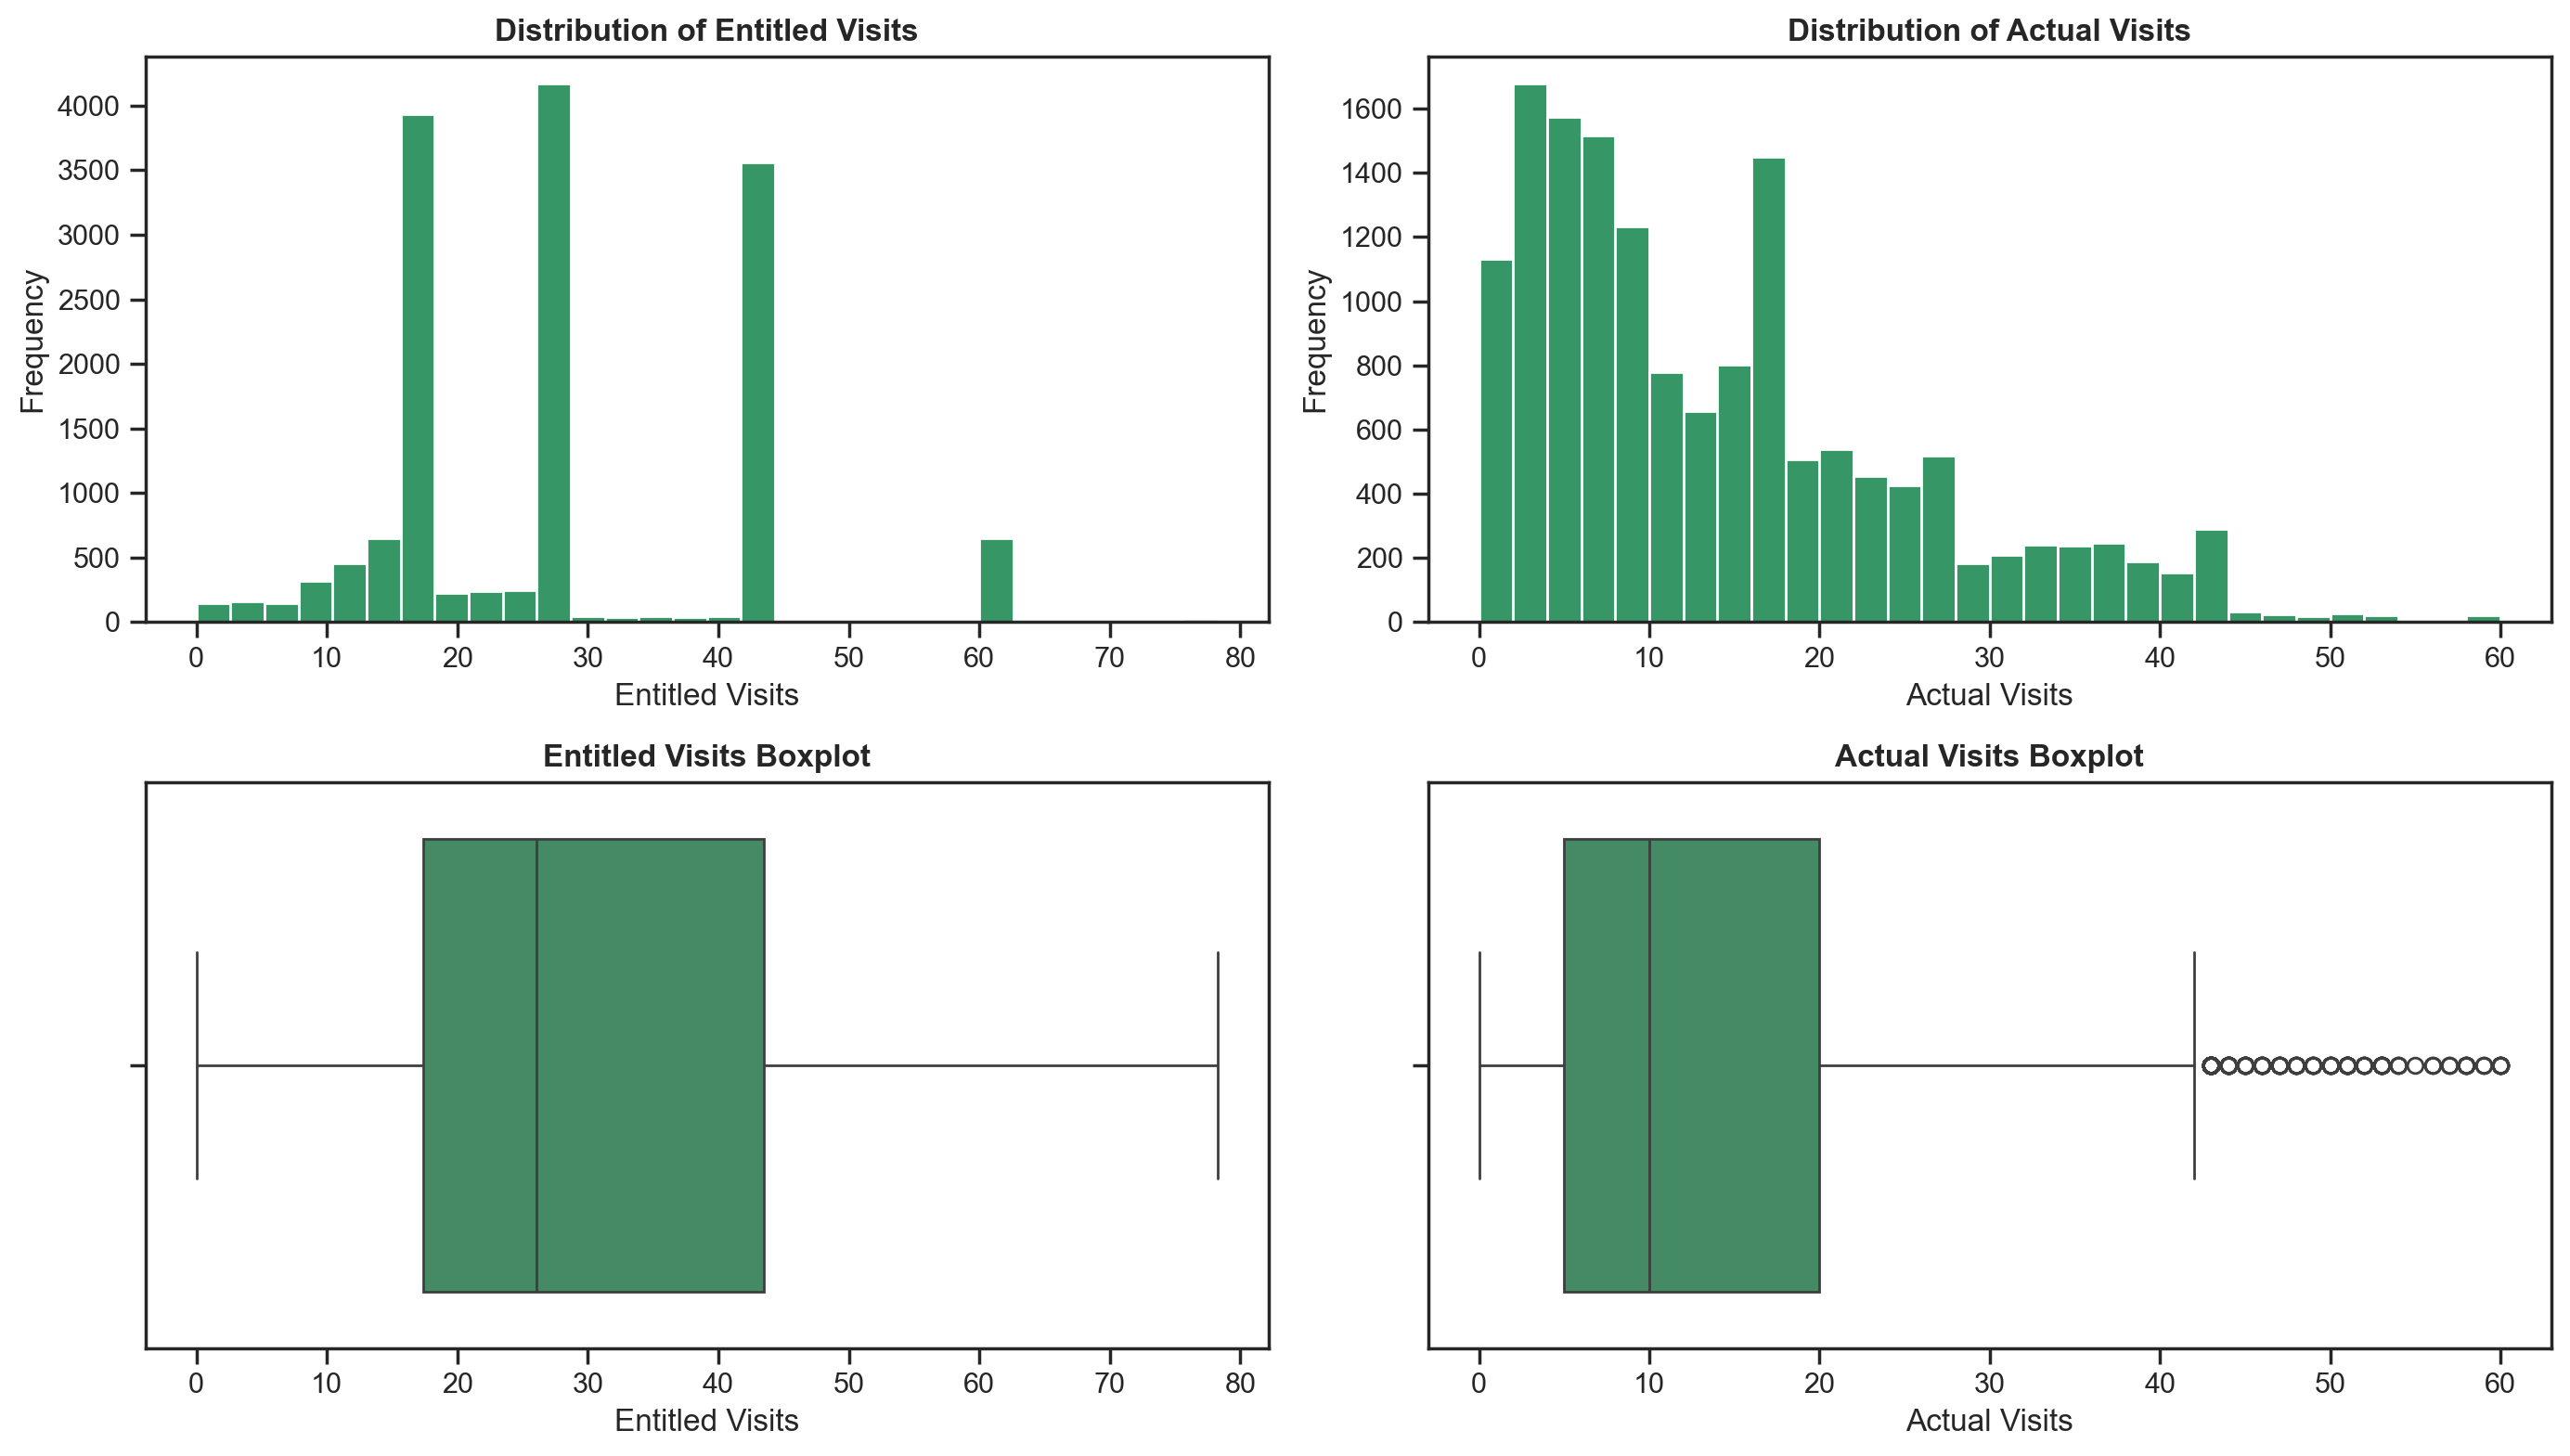

In [125]:
subplot_figsize = (14, 8) 

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(
        2, # nrows
        2, # ncols
        figsize=subplot_figsize)

axes[0, 0].hist(df_nodups["entitled_visits_last_period"].dropna(), bins=30, color=main_color)
axes[0, 1].hist(df_nodups["actual_visits_last_period"].dropna(), bins=30, color=main_color)

sns.boxplot(x=df_nodups["entitled_visits_last_period"], color=main_color, ax=axes[1, 0])
sns.boxplot(x=df_nodups["actual_visits_last_period"], color=main_color, ax=axes[1, 1])

axes[0, 0].set_title('Distribution of Entitled Visits', fontweight="bold") 
axes[0, 0].set_xlabel('Entitled Visits')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].set_title('Distribution of Actual Visits', fontweight="bold") 
axes[0, 1].set_xlabel('Actual Visits')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].set_title('Entitled Visits Boxplot', fontweight="bold") 
axes[1, 0].set_xlabel('Entitled Visits')

axes[1, 1].set_title('Actual Visits Boxplot', fontweight="bold") 
axes[1, 1].set_xlabel('Actual Visits')

plt.tight_layout()
plt.show()


#taxa de utilização: se os clientes estão a esgotar os seus planos ou se estão a subutilizar o espaço (pagam por X dias, mas só vão a Y).

### 3.1.7. meeting_room_hours and event_space_hours

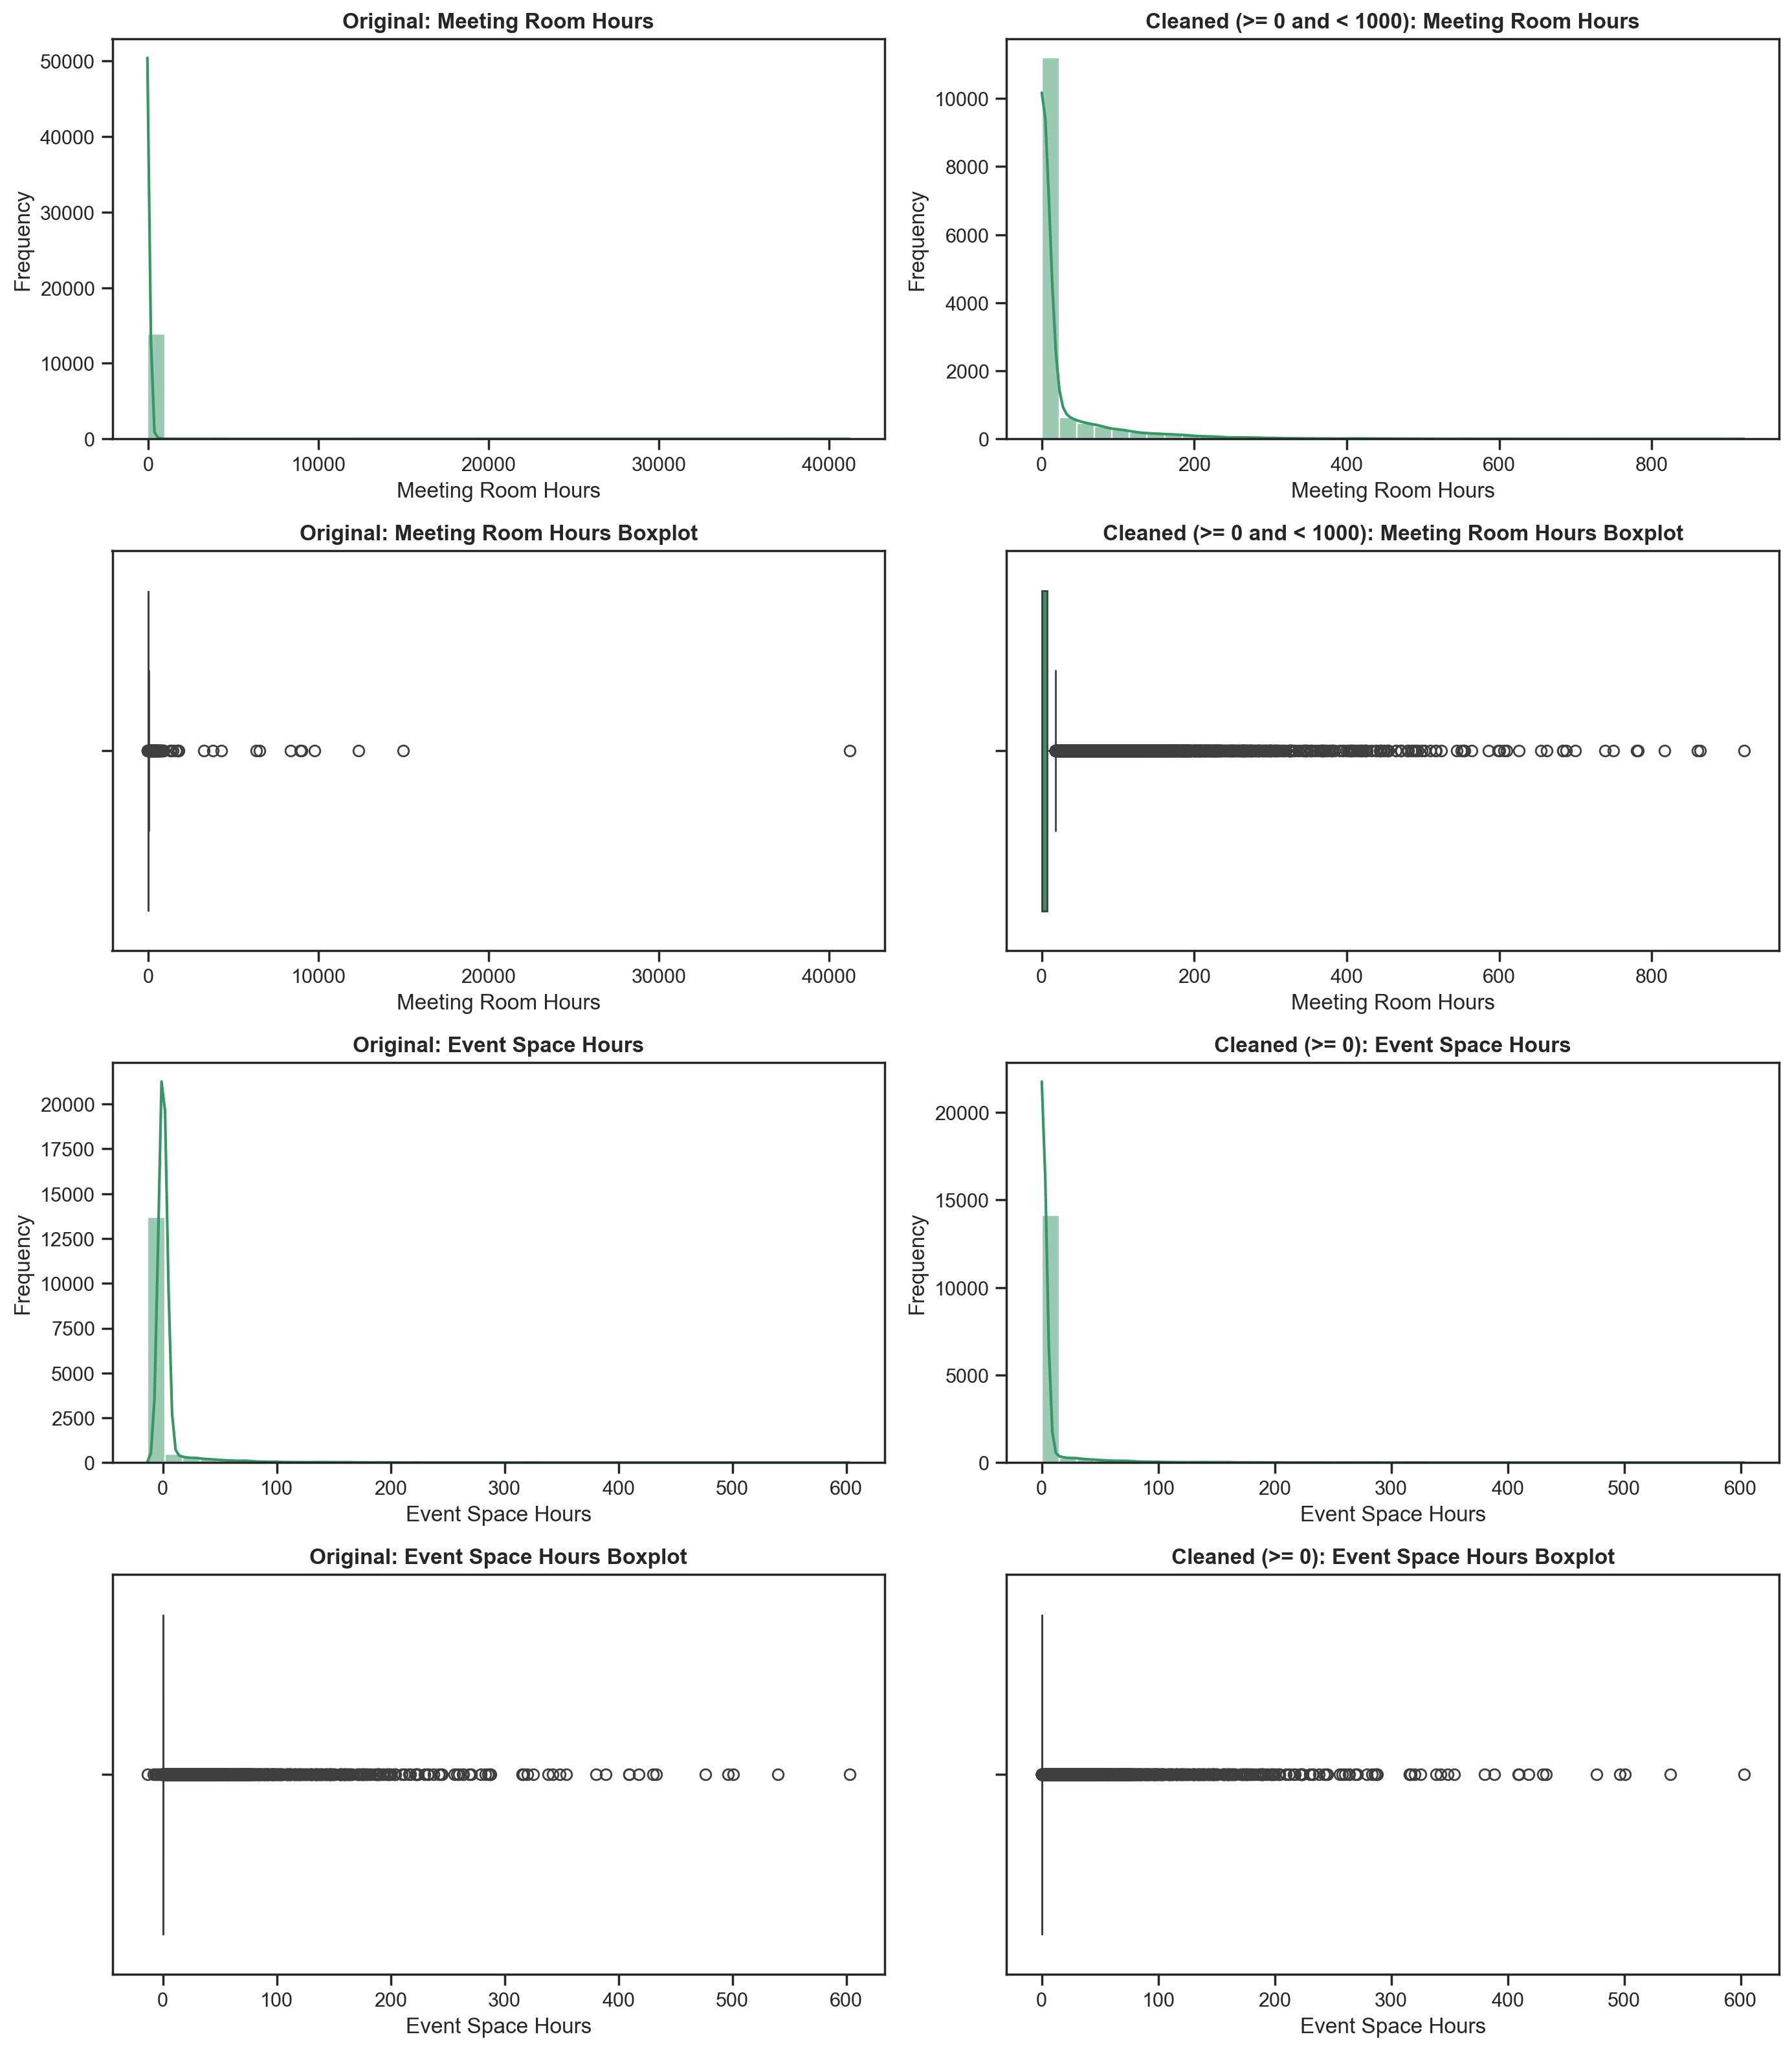

In [131]:
df_meeting_clean = df_nodups[(df_nodups["meeting_room_hours"] >= 0) & (df_nodups["meeting_room_hours"] < 1000)]
# upper boundary of 1,000 hours was applied to remove extreme system anomalies (including a 40,000-hour record)
df_event_clean = df_nodups[df_nodups["event_space_hours"] >= 0]

subplot_figsize = (14, 16) 

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(
        4, # nrows
        2, # ncols
        figsize=subplot_figsize)

# meeting_room_hours
sns.histplot(df_nodups["meeting_room_hours"].dropna(), bins=40, color=main_color, kde=True, ax=axes[0, 0])
sns.histplot(df_meeting_clean["meeting_room_hours"].dropna(), bins=40, color=main_color, kde=True, ax=axes[0, 1])

sns.boxplot(x=df_nodups["meeting_room_hours"], color=main_color, ax=axes[1, 0])
sns.boxplot(x=df_meeting_clean["meeting_room_hours"], color=main_color, ax=axes[1, 1])

# event_space_hours
sns.histplot(df_nodups["event_space_hours"].dropna(), bins=40, color=main_color, kde=True, ax=axes[2, 0])
sns.histplot(df_event_clean["event_space_hours"].dropna(), bins=40, color=main_color, kde=True, ax=axes[2, 1])

sns.boxplot(x=df_nodups["event_space_hours"], color=main_color, ax=axes[3, 0])
sns.boxplot(x=df_event_clean["event_space_hours"], color=main_color, ax=axes[3, 1])


axes[0, 0].set_title('Original: Meeting Room Hours', fontweight="bold") 
axes[0, 0].set_xlabel('Meeting Room Hours')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].set_title('Cleaned (>= 0 and < 1000): Meeting Room Hours', fontweight="bold") 
axes[0, 1].set_xlabel('Meeting Room Hours')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].set_title('Original: Meeting Room Hours Boxplot', fontweight="bold") 
axes[1, 0].set_xlabel('Meeting Room Hours')

axes[1, 1].set_title('Cleaned (>= 0 and < 1000): Meeting Room Hours Boxplot', fontweight="bold") 
axes[1, 1].set_xlabel('Meeting Room Hours')

axes[2, 0].set_title('Original: Event Space Hours', fontweight="bold") 
axes[2, 0].set_xlabel('Event Space Hours')
axes[2, 0].set_ylabel('Frequency')

axes[2, 1].set_title('Cleaned (>= 0): Event Space Hours', fontweight="bold") 
axes[2, 1].set_xlabel('Event Space Hours')
axes[2, 1].set_ylabel('Frequency')

axes[3, 0].set_title('Original: Event Space Hours Boxplot', fontweight="bold") 
axes[3, 0].set_xlabel('Event Space Hours')

axes[3, 1].set_title('Cleaned (>= 0): Event Space Hours Boxplot', fontweight="bold") 
axes[3, 1].set_xlabel('Event Space Hours')


plt.tight_layout()
plt.show()

### 3.1.7. guest_passes_issued	

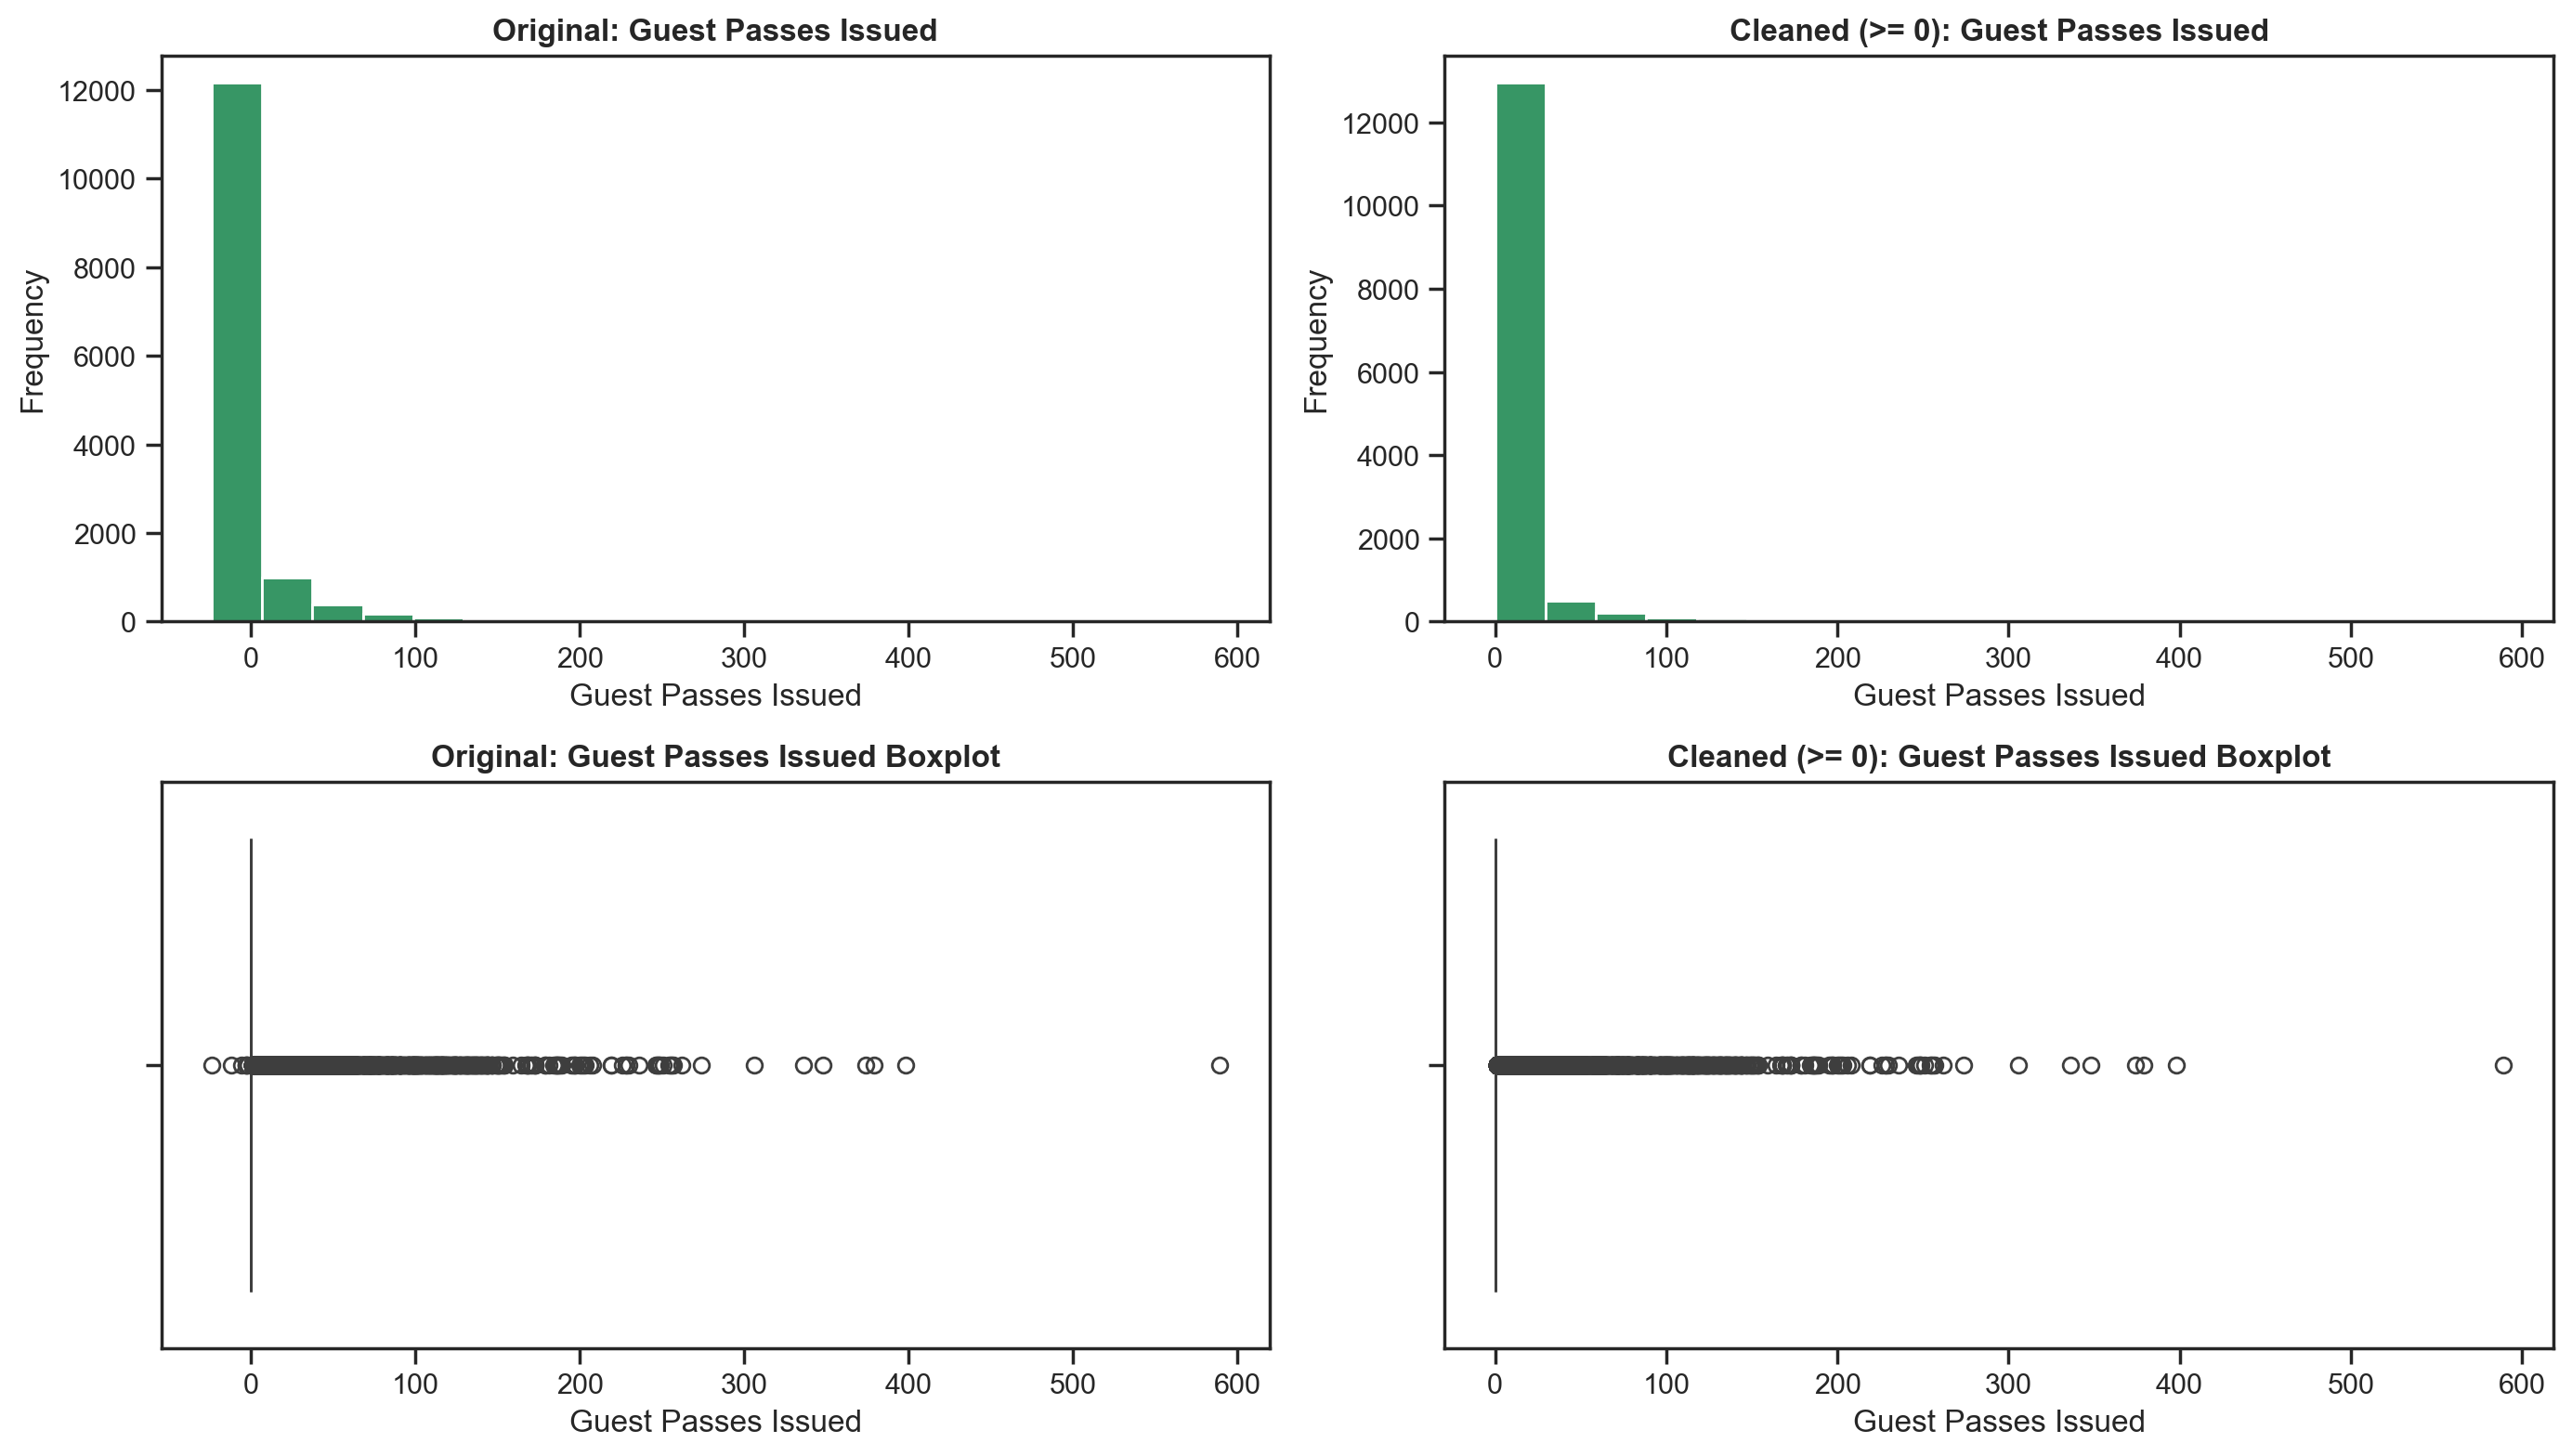

In [133]:
df_guests_clean = df_nodups[df_nodups["guest_passes_issued"] >= 0]

subplot_figsize = (14, 8)

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(
        2, # nrows
        2, # ncols
        figsize=subplot_figsize)

axes[0, 0].hist(df_nodups["guest_passes_issued"].dropna(), bins=20, color=main_color)
axes[0, 1].hist(df_guests_clean["guest_passes_issued"].dropna(), bins=20, color=main_color)

sns.boxplot(x=df_nodups["guest_passes_issued"], color=main_color, ax=axes[1, 0])
sns.boxplot(x=df_guests_clean["guest_passes_issued"], color=main_color, ax=axes[1, 1])

axes[0, 0].set_title('Original: Guest Passes Issued', fontweight="bold")
axes[0, 0].set_xlabel('Guest Passes Issued')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].set_title('Cleaned (>= 0): Guest Passes Issued', fontweight="bold")
axes[0, 1].set_xlabel('Guest Passes Issued')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].set_title('Original: Guest Passes Issued Boxplot', fontweight="bold")
axes[1, 0].set_xlabel('Guest Passes Issued')

axes[1, 1].set_title('Cleaned (>= 0): Guest Passes Issued Boxplot', fontweight="bold")
axes[1, 1].set_xlabel('Guest Passes Issued')

plt.tight_layout()
plt.show()

### 3.1.8. n_renewals

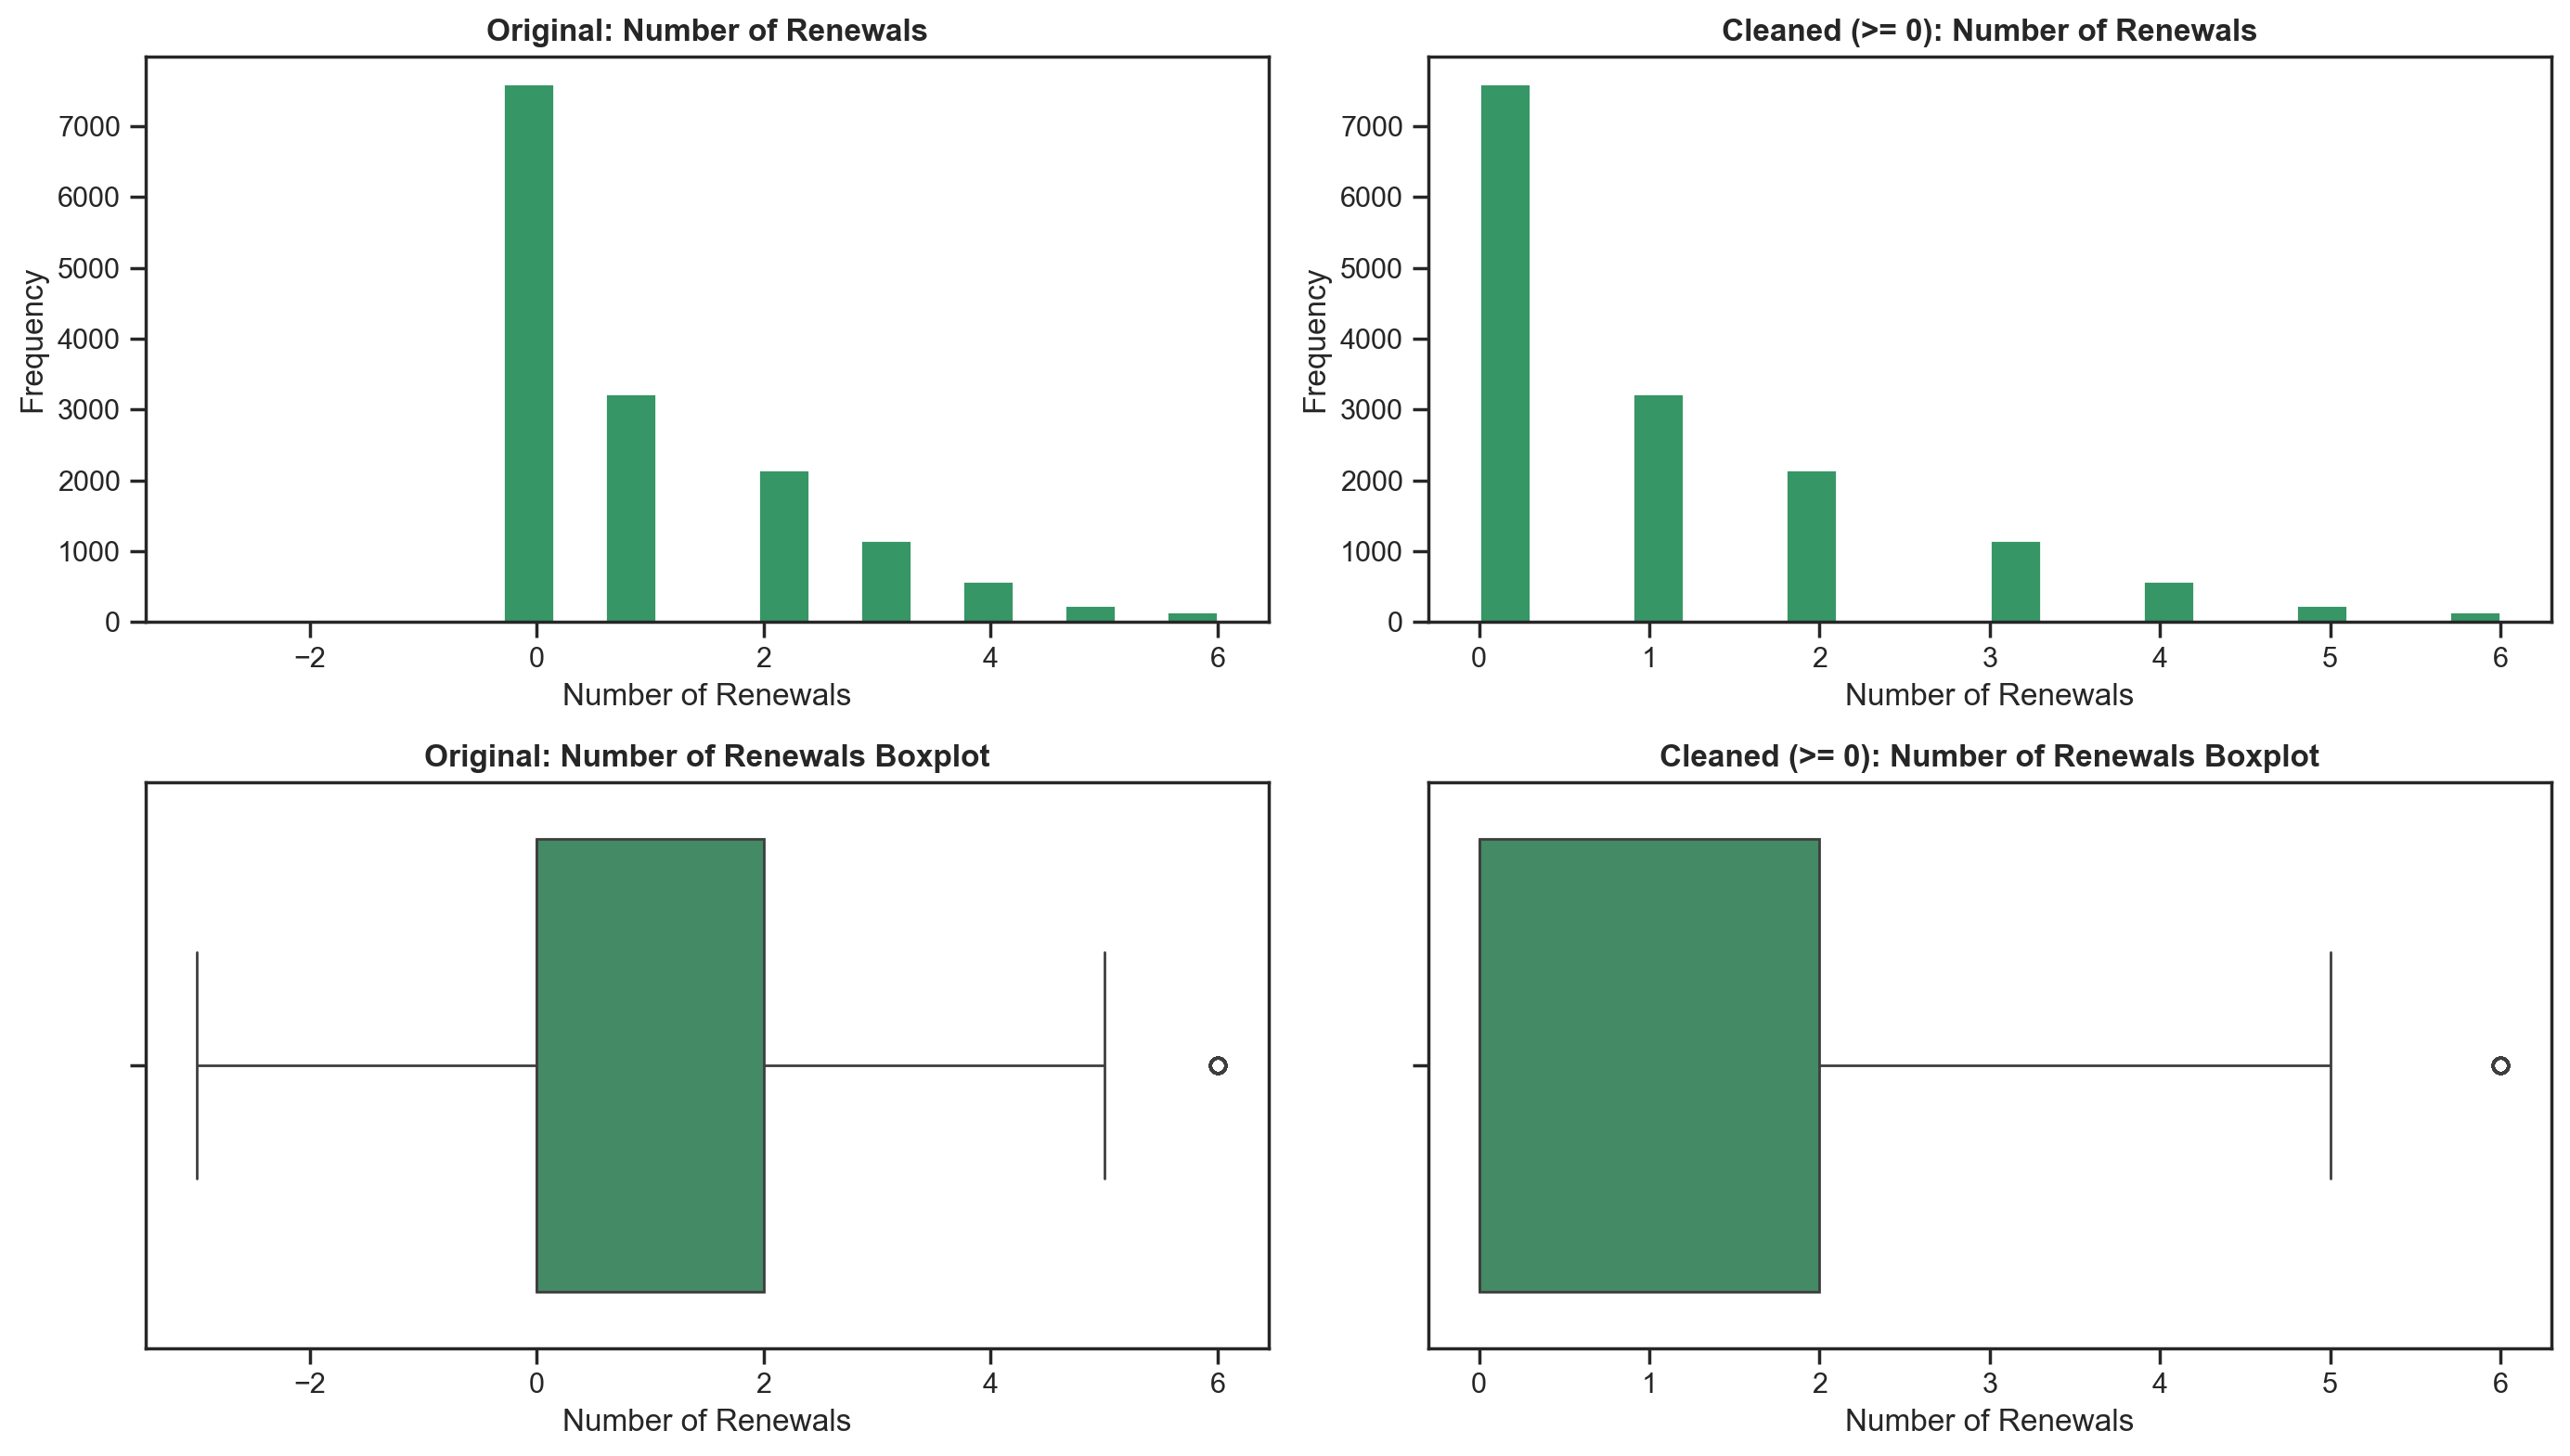

In [128]:
df_renewals_clean = df_nodups[df_nodups["n_renewals"] >= 0]

subplot_figsize = (14, 8)

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(
        2, # nrows
        2, # ncols
        figsize=subplot_figsize)

axes[0, 0].hist(df_nodups["n_renewals"].dropna(), bins=20, color=main_color)
axes[0, 1].hist(df_renewals_clean["n_renewals"].dropna(), bins=20, color=main_color)

sns.boxplot(x=df_nodups["n_renewals"], color=main_color, ax=axes[1, 0])
sns.boxplot(x=df_renewals_clean["n_renewals"], color=main_color, ax=axes[1, 1])

axes[0, 0].set_title('Original: Number of Renewals', fontweight="bold")
axes[0, 0].set_xlabel('Number of Renewals')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].set_title('Cleaned (>= 0): Number of Renewals', fontweight="bold")
axes[0, 1].set_xlabel('Number of Renewals')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].set_title('Original: Number of Renewals Boxplot', fontweight="bold")
axes[1, 0].set_xlabel('Number of Renewals')

axes[1, 1].set_title('Cleaned (>= 0): Number of Renewals Boxplot', fontweight="bold")
axes[1, 1].set_xlabel('Number of Renewals')

plt.tight_layout()
plt.show()

## 3.2. Correlation Matrix

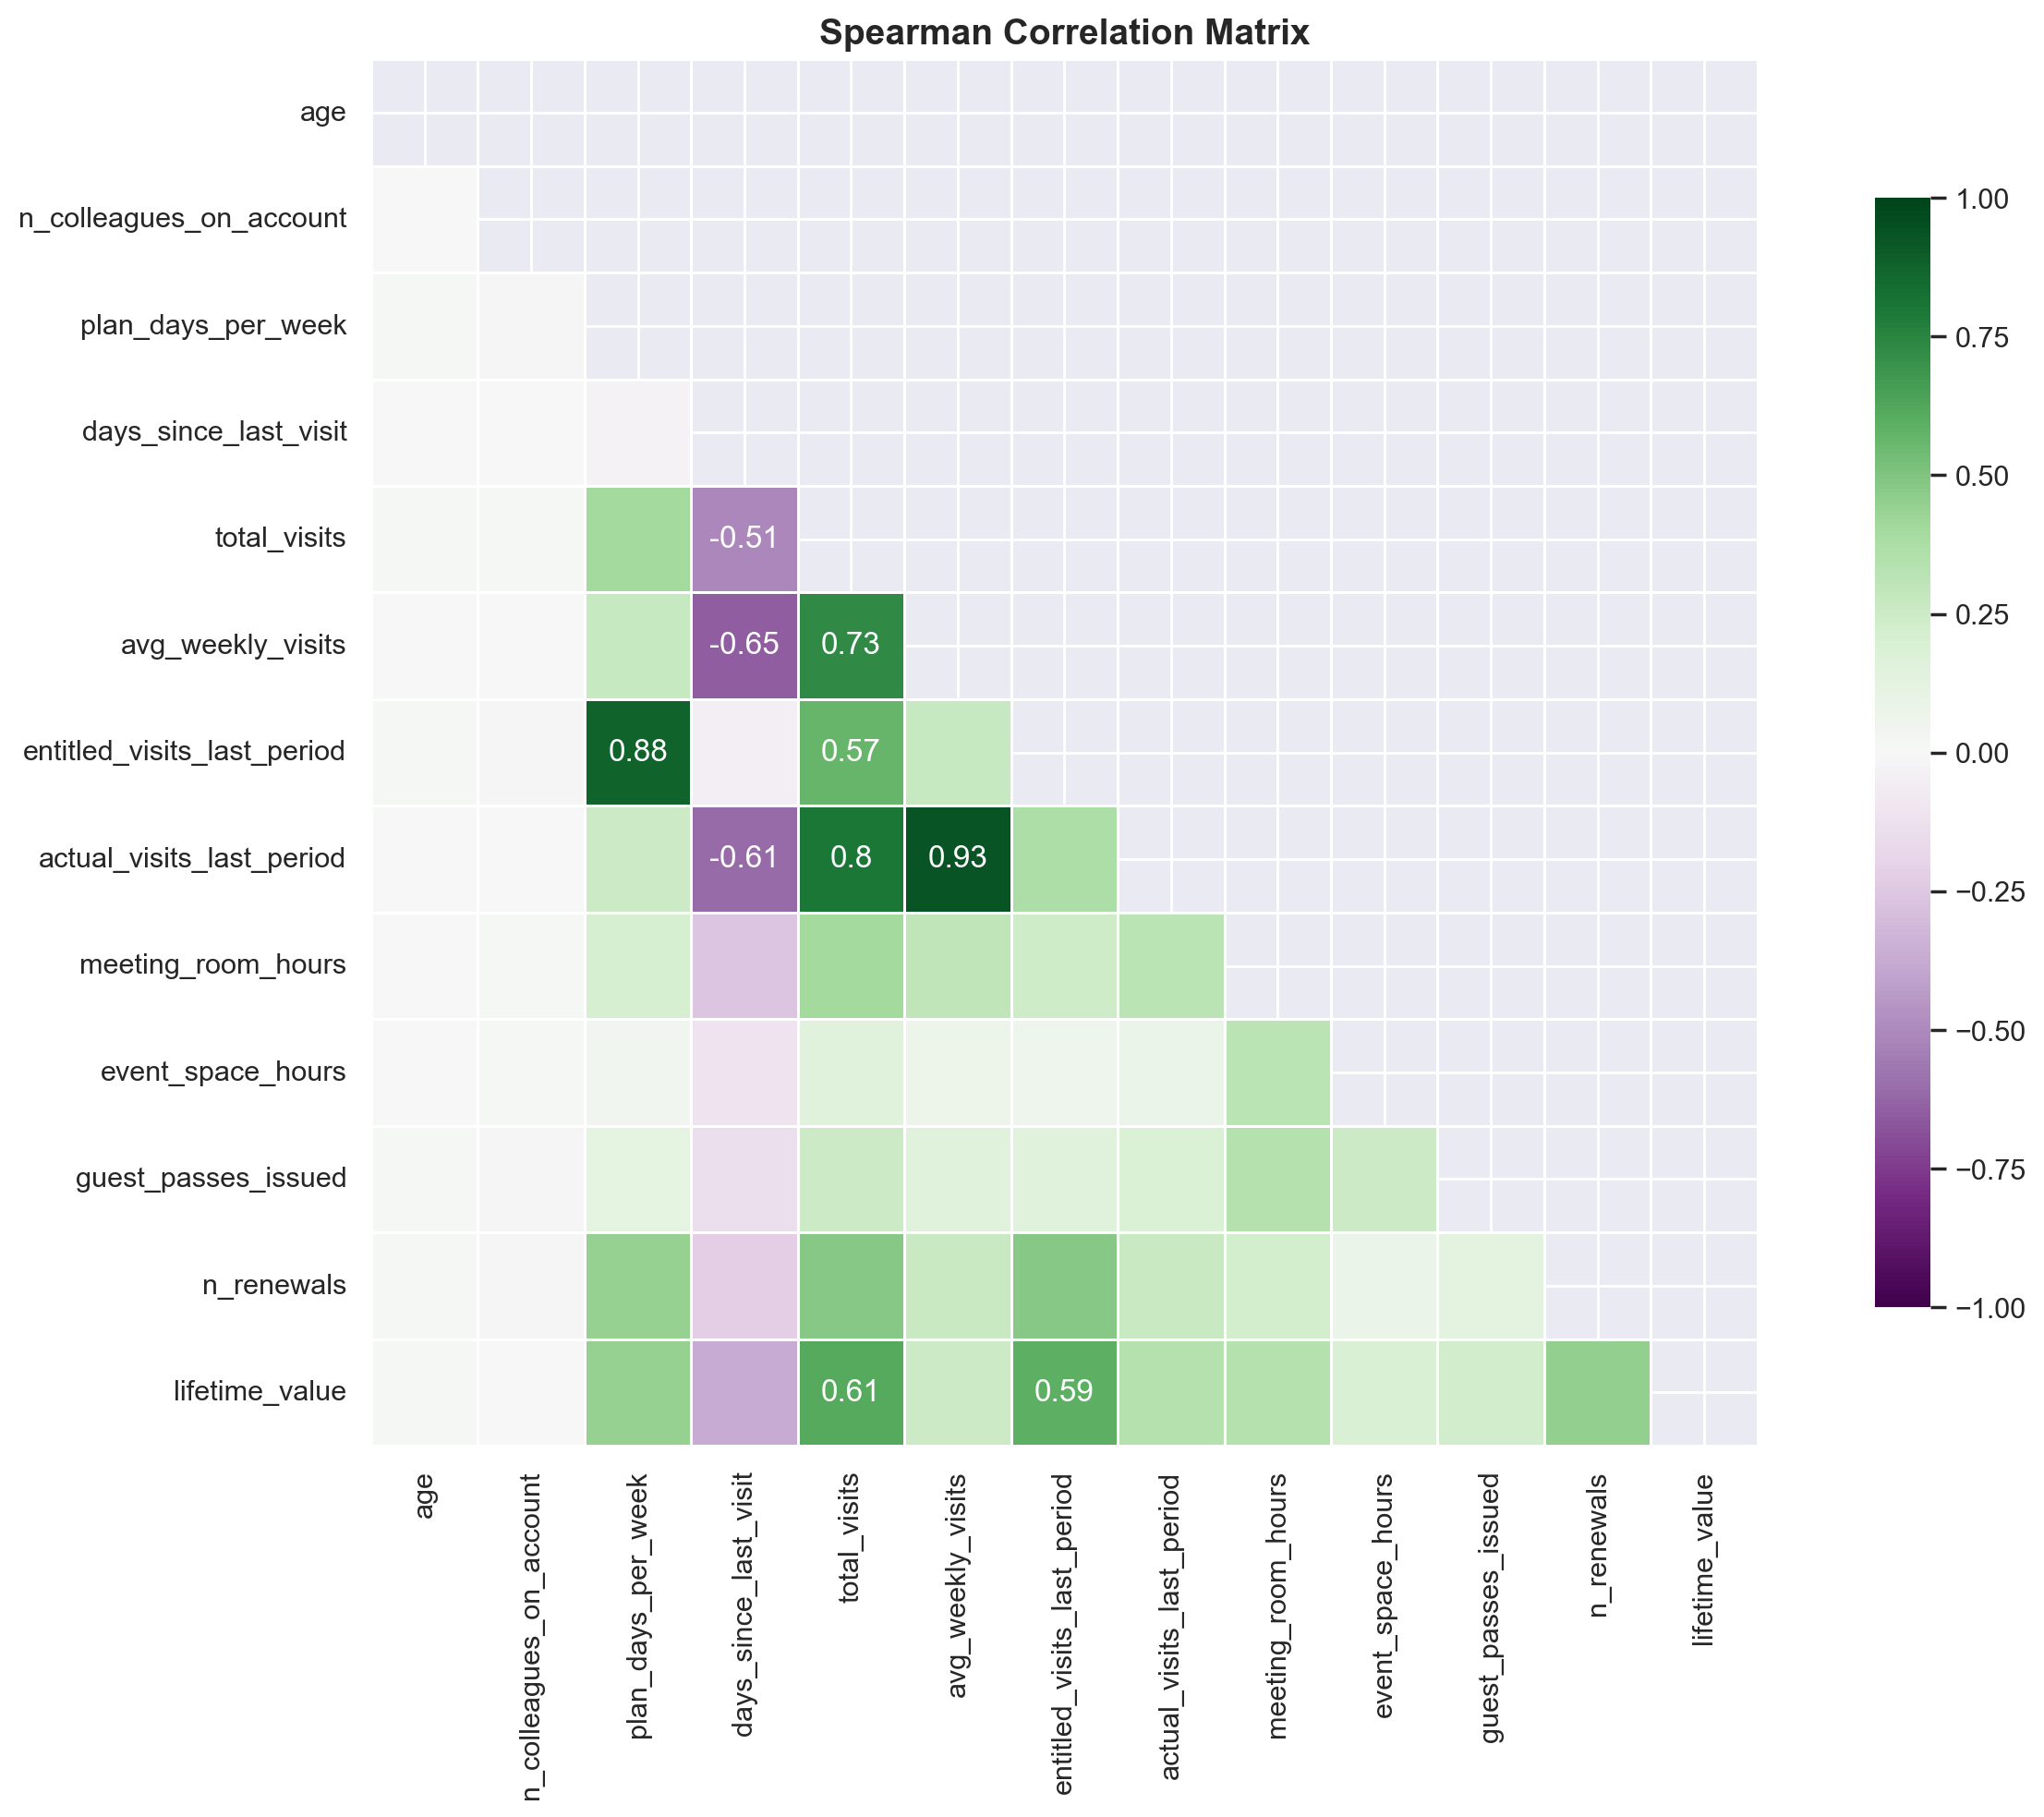

In [138]:
corr = df_nodups[metric_features].corr(method="spearman").round(2)

# Lógica da aula para anotar apenas correlações fortes (>= 0.5 ou <= -0.5)
mask_annot = np.absolute(corr.values) >= 0.5 
annot = np.where(mask_annot, corr.values, np.full(corr.shape,"")) 

mask_upper = np.triu(np.ones_like(corr, dtype=bool))

fig = plt.figure(figsize=(14, 10))

sns.heatmap(
    data=corr, 
    annot=annot, 
    fmt='s', 
    mask=mask_upper,         
    vmin=-1, vmax=1, 
    center=0, 
    square=True, 
    linewidths=.5, 
    cmap='PRGn',              
    cbar_kws={"shrink": .8}   
)

plt.title("Spearman Correlation Matrix", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

## 3.3. Bivariate Analysis